In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU found. Recheck the Colab runtime settings.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4
CUDA version: 13.0


In [ ]:
from pathlib import Path
import torch

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CSBP441_Coral_Project"
)

BALANCED_DATA_YAML = (
    PROJECT_ROOT
    / "data_balanced"
    / "Coral-Detection-35class-balanced"
    / "data.yaml"
)

print("GPU available:", torch.cuda.is_available())
print("Project folder found:", PROJECT_ROOT.is_dir())
print("Balanced data.yaml found:", BALANCED_DATA_YAML.is_file())

GPU available: True
Project folder found: True
Balanced data.yaml found: True


In [ ]:
import yaml
import importlib.metadata as metadata

source_config = yaml.safe_load(BALANCED_DATA_YAML.read_text())

print("=== Balanced dataset settings ===")
print(yaml.safe_dump(source_config, sort_keys=False))

config_path = PROJECT_ROOT / "configs" / "baseline_config.yaml"

print("=== Saved baseline training settings ===")
if config_path.is_file():
    print(config_path.read_text())
else:
    print("Baseline configuration file not found.")

print("=== Ultralytics version ===")
try:
    print(metadata.version("ultralytics"))
except metadata.PackageNotFoundError:
    print("Not installed in this runtime.")

scripts = sorted(
    PROJECT_ROOT.rglob("disable_default_albumentations.py")
)

print("\n=== Augmentation-control scripts ===")
print("Found:", len(scripts))
for script in scripts:
    print(script)

if len(scripts) == 1:
    DISABLE_AUG_SCRIPT = scripts[0]
    print("\n=== Script contents ===")
    print(DISABLE_AUG_SCRIPT.read_text())

=== Balanced dataset settings ===
train: train/images
val: valid/images
test: test/images
nc: 35
names:
- Acanthastrea
- Acropora
- Anacropa
- Astreopora
- Australogyra
- Cliona
- Coeloseris
- Coscinaraea
- Cycloseris
- Echinophyllia
- Euphyllia
- Favia
- Favites
- Galaxea
- Goniastrea
- Heliopora
- Heterocyathus
- Isopora
- Leptoseris
- Lobophyllia
- Millepora
- Montastraea
- Montipora
- Oulophyllia
- Pachyseris speciosa
- Pavona
- Pectinia
- Pocillopora- Job 1
- Porites
- Psammocora
- Sandalolitha
- Stylophora
- Symphyllia- Job 2
- Trachyphilia
- Zoopilus

=== Saved baseline training settings ===
model: yolov8n.pt
epochs: 50
imgsz: 640
batch: 16
seed: 42
deterministic: true
optimizer: AdamW
lr0: 0.001
weight_decay: 0.0005
patience: 0
workers: 2
pretrained: true
save: true
save_period: 1
hsv_h: 0.0
hsv_s: 0.0
hsv_v: 0.0
fliplr: 0.5
mosaic: 1.0
mixup: 0.0

=== Ultralytics version ===
Not installed in this runtime.

=== Augmentation-control scripts ===
Found: 1
/content/drive/MyDrive/CS

In [ ]:
from pathlib import Path
import yaml

# Restore key paths after the GPU runtime restart.
PROJECT_ROOT = Path("/content/drive/MyDrive/CSBP441_Coral_Project")

BALANCED_DATASET = (
    PROJECT_ROOT
    / "data_balanced"
    / "Coral-Detection-35class-balanced"
)

BALANCED_DATA_YAML = BALANCED_DATASET / "data.yaml"

assert BALANCED_DATA_YAML.exists(), "Balanced data.yaml was not found."

# These settings must remain identical for baseline, white balance,
# CLAHE, and combined-pipeline experiments.
baseline_config = {
    "model": "yolov8n.pt",
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "seed": 42,
    "deterministic": True,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "weight_decay": 0.0005,
    "patience": 0,
    "workers": 2,
    "pretrained": True,
    "save": True,
    "save_period": 1,

    # Keep color augmentation disabled so it does not imitate
    # white balance or CLAHE. Geometric augmentation stays identical
    # in all four experiments.
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "fliplr": 0.5,
    "mosaic": 1.0,
    "mixup": 0.0,
}

CONFIG_PATH = PROJECT_ROOT / "configs" / "baseline_config.yaml"

with open(CONFIG_PATH, "w") as file:
    yaml.safe_dump(baseline_config, file, sort_keys=False)

print("Balanced dataset YAML:")
print(BALANCED_DATA_YAML)

print("\nSaved baseline configuration:")
print(CONFIG_PATH)

print("\nConfiguration:")
print(yaml.safe_dump(baseline_config, sort_keys=False))

Balanced dataset YAML:
/content/drive/MyDrive/CSBP441_Coral_Project/data_balanced/Coral-Detection-35class-balanced/data.yaml

Saved baseline configuration:
/content/drive/MyDrive/CSBP441_Coral_Project/configs/baseline_config.yaml

Configuration:
model: yolov8n.pt
epochs: 50
imgsz: 640
batch: 16
seed: 42
deterministic: true
optimizer: AdamW
lr0: 0.001
weight_decay: 0.0005
patience: 0
workers: 2
pretrained: true
save: true
save_period: 1
hsv_h: 0.0
hsv_s: 0.0
hsv_v: 0.0
fliplr: 0.5
mosaic: 1.0
mixup: 0.0



In [ ]:
%pip install -q ultralytics==8.4.207

In [ ]:
from ultralytics.data.utils import check_det_dataset

# Check that Ultralytics can locate the train, validation, and test data.
dataset_info = check_det_dataset(
    str(BALANCED_DATA_YAML),
    autodownload=False
)

print("Classes:", dataset_info["nc"])
print("Train path:", dataset_info["train"])
print("Validation path:", dataset_info["val"])
print("Test path:", dataset_info["test"])

print("\nFirst 5 class names:")
for class_id, class_name in list(dataset_info["names"].items())[:5]:
    print(f"{class_id}: {class_name}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Classes: 35
Train path: /content/drive/MyDrive/CSBP441_Coral_Project/data_balanced/Coral-Detection-35class-balanced/train/images
Validation path: /content/drive/MyDrive/CSBP441_Coral_Project/data_balanced/Coral-Detection-35class-balanced/valid/images
Test path: /content/drive/MyDrive/CSBP441_Coral_Project/data_balanced/Coral-Detection-35class-balanced/test/images

First 5 class names:
0: Acanthastrea
1: Acropora
2: Anacropa
3: Astreopora
4: Australogyra


In [ ]:
import shutil
from pathlib import Path

LOCAL_BALANCED_DATASET = Path("/content/Coral-Detection-35class-balanced")
LOCAL_DATA_YAML = LOCAL_BALANCED_DATASET / "data.yaml"

if LOCAL_BALANCED_DATASET.exists():
    print("Local training copy already exists:")
    print(LOCAL_BALANCED_DATASET)
else:
    print("Copying balanced dataset from Drive to local Colab storage...")
    shutil.copytree(BALANCED_DATASET, LOCAL_BALANCED_DATASET)
    print("Local copy complete.")

print("\nLocal data.yaml exists:", LOCAL_DATA_YAML.exists())

for split in ["train", "valid", "test"]:
    image_count = len(list((LOCAL_BALANCED_DATASET / split / "images").glob("*")))
    label_count = len(list((LOCAL_BALANCED_DATASET / split / "labels").glob("*.txt")))
    print(f"{split}: {image_count} images, {label_count} labels")

Copying balanced dataset from Drive to local Colab storage...
Local copy complete.

Local data.yaml exists: True
train: 3390 images, 3390 labels
valid: 397 images, 397 labels
test: 169 images, 169 labels


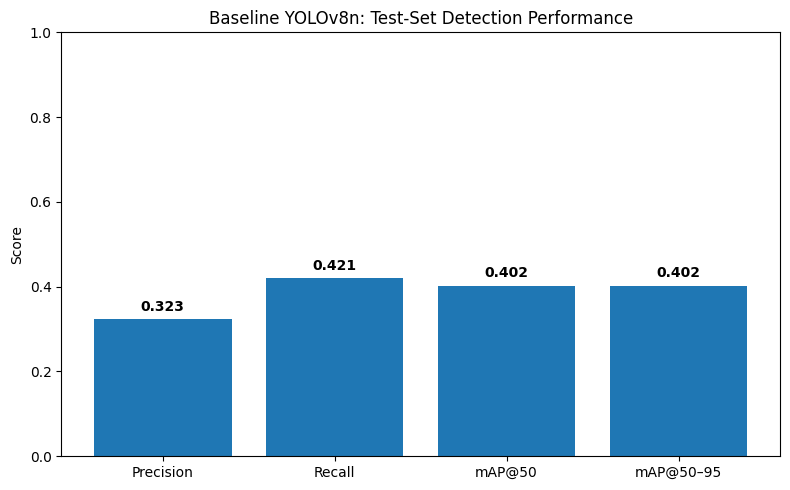

Saved: /content/drive/MyDrive/CSBP441_Coral_Project/results_figures/baseline_test_overall_metrics.png


In [ ]:
# Baseline overall test metrics graph
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

metrics_path = (
    PROJECT_ROOT / "baseline" / "runs" /
    "yolov8n_baseline_35class_seed42" / "test_metrics_summary.json"
)

with open(metrics_path, "r") as file:
    metrics = json.load(file)

plot_data = pd.DataFrame({
    "Metric": ["Precision", "Recall", "mAP@50", "mAP@50–95"],
    "Score": [
        metrics["precision"],
        metrics["recall"],
        metrics["mAP50"],
        metrics["mAP50_95"]
    ]
})

plt.figure(figsize=(8, 5))
bars = plt.bar(plot_data["Metric"], plot_data["Score"], color="#1f77b4")

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Baseline YOLOv8n: Test-Set Detection Performance")

for bar, score in zip(bars, plot_data["Score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.3f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

output_path = PROJECT_ROOT / "results_figures" / "baseline_test_overall_metrics.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

['class_id', 'class_name', 'test_instances', 'precision', 'recall', 'mAP50', 'mAP50_95']


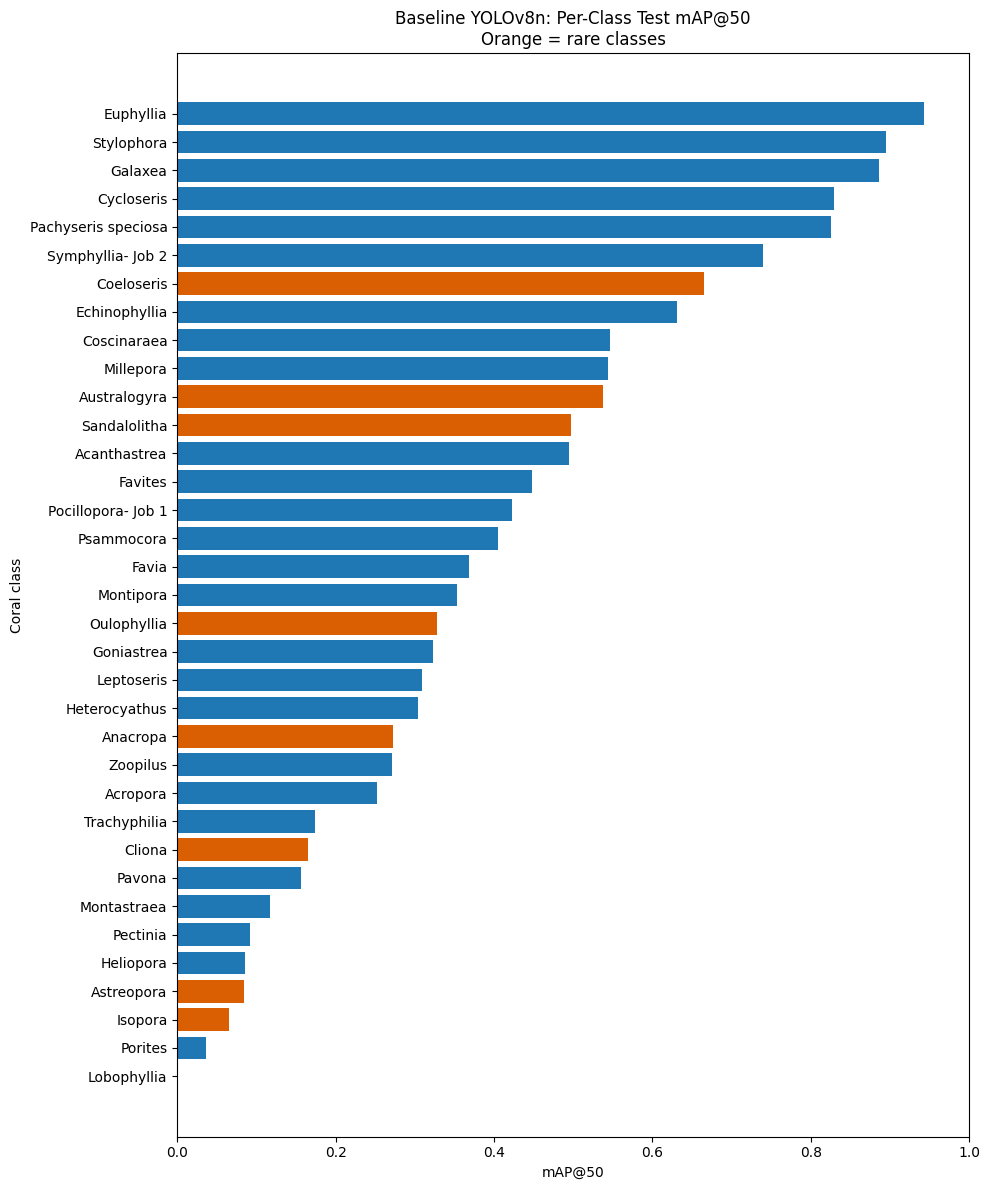

Saved: /content/drive/MyDrive/CSBP441_Coral_Project/results_figures/baseline_per_class_map50.png


In [ ]:
# Per-class mAP@50 graph for the baseline test set
import pandas as pd
import matplotlib.pyplot as plt

per_class_path = (
    PROJECT_ROOT / "baseline" / "runs" /
    "yolov8n_baseline_35class_seed42" / "test_per_class_metrics.csv"
)

per_class = pd.read_csv(per_class_path)

# Check the available column names once
print(per_class.columns.tolist())

# Sort classes by mAP@50
per_class = per_class.sort_values("mAP50", ascending=True)

plt.figure(figsize=(10, 12))
colors = ["#d95f02" if name in [
    "Anacropa", "Astreopora", "Australogyra", "Cliona",
    "Coeloseris", "Isopora", "Lobophyllia", "Oulophyllia",
    "Sandalolitha"
] else "#1f77b4" for name in per_class["class_name"]]

plt.barh(per_class["class_name"], per_class["mAP50"], color=colors)
plt.xlim(0, 1)
plt.xlabel("mAP@50")
plt.ylabel("Coral class")
plt.title("Baseline YOLOv8n: Per-Class Test mAP@50\nOrange = rare classes")

plt.tight_layout()

output_path = PROJECT_ROOT / "results_figures" / "baseline_per_class_map50.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output_path)

# CLAHE-only experiment

## Set up the CLAHE-only experiment

In [ ]:
# CLAHE experiment setup for six validation-tuning candidates.
# This cell creates output folders and records the parameter grid only.
# It does not modify the source dataset, images, labels, or splits.

from pathlib import Path
import json
import yaml

# Confirm the shared setup cells have completed.
assert "PROJECT_ROOT" in globals()
assert "BALANCED_DATA_YAML" in globals()
assert "LOCAL_BALANCED_DATASET" in globals()

assert BALANCED_DATA_YAML == (
    PROJECT_ROOT
    / "data_balanced"
    / "Coral-Detection-35class-balanced"
    / "data.yaml"
)
assert BALANCED_DATA_YAML.exists()
assert LOCAL_BALANCED_DATASET.exists()

# Read and verify the source dataset configuration.
source_config = yaml.safe_load(BALANCED_DATA_YAML.read_text())

class_count = source_config.get(
    "nc",
    len(source_config.get("names", []))
)
assert class_count == 35, f"Expected 35 classes, found {class_count}"

# All persistent outputs go under the new clahe folder.
CLAHE_ROOT = PROJECT_ROOT / "clahe"
CLAHE_TUNING_ROOT = CLAHE_ROOT / "tuning"
CLAHE_FINAL_DATASET = CLAHE_ROOT / "final_dataset"
CLAHE_RUNS = CLAHE_ROOT / "runs"
CLAHE_RESULTS = CLAHE_ROOT / "results"
CLAHE_FIGURES = CLAHE_ROOT / "figures"
CLAHE_PREDICTIONS = CLAHE_ROOT / "predictions"
CLAHE_TIMING = CLAHE_ROOT / "timing"

for output_dir in [
    CLAHE_ROOT,
    CLAHE_TUNING_ROOT,
    CLAHE_FINAL_DATASET,
    CLAHE_RUNS,
    CLAHE_RESULTS,
    CLAHE_FIGURES,
    CLAHE_PREDICTIONS,
    CLAHE_TIMING,
]:
    output_dir.mkdir(parents=True, exist_ok=True)

# The six CLAHE settings specified in the proposal.
CLAHE_GRID = []

for clip_limit in [1.0, 2.0, 3.0]:
    for tile_grid_size in [(4, 4), (8, 8)]:
        grid_name = (
            f"clip{clip_limit:g}_"
            f"grid{tile_grid_size[0]}x{tile_grid_size[1]}"
        )

        candidate_root = CLAHE_TUNING_ROOT / grid_name
        candidate_dataset = candidate_root / "dataset"
        candidate_run = candidate_root / "run"
        candidate_results = candidate_root / "results"

        for candidate_dir in [
            candidate_root,
            candidate_dataset,
            candidate_run,
            candidate_results,
        ]:
            candidate_dir.mkdir(parents=True, exist_ok=True)

        CLAHE_GRID.append({
            "name": grid_name,
            "clip_limit": clip_limit,
            "tile_grid_size": list(tile_grid_size),
            "root": str(candidate_root),
            "dataset": str(candidate_dataset),
            "run": str(candidate_run),
            "results": str(candidate_results),
        })

# Save the fixed candidate grid inside clahe/.
CLAHE_GRID_PATH = CLAHE_ROOT / "clahe_parameter_grid.json"
CLAHE_GRID_PATH.write_text(
    json.dumps(CLAHE_GRID, indent=2)
)

# Locate the required script. It must be executed before model.train().
script_candidates = sorted(
    PROJECT_ROOT.rglob("disable_default_albumentations.py")
)

if len(script_candidates) == 0:
    raise FileNotFoundError(
        "Could not find disable_default_albumentations.py "
        "under PROJECT_ROOT."
    )

if len(script_candidates) > 1:
    print("Multiple candidate scripts found:")
    for candidate in script_candidates:
        print(" -", candidate)
    raise RuntimeError(
        "Multiple augmentation-control scripts found."
    )

DISABLE_AUG_SCRIPT = script_candidates[0]

print("Source data.yaml:")
print(BALANCED_DATA_YAML)

print("\nNumber of classes:", class_count)
print("Number of CLAHE candidates:", len(CLAHE_GRID))

print("\nCandidate settings:")
for candidate in CLAHE_GRID:
    print(
        f" - {candidate['name']}: "
        f"clipLimit={candidate['clip_limit']}, "
        f"tileGridSize={tuple(candidate['tile_grid_size'])}"
    )

print("\nCLAHE output root:")
print(CLAHE_ROOT)

print("\nSaved parameter grid:")
print(CLAHE_GRID_PATH)

print("\nRequired augmentation-control script:")
print(DISABLE_AUG_SCRIPT)

Source data.yaml:
/content/drive/MyDrive/CSBP441_Coral_Project/data_balanced/Coral-Detection-35class-balanced/data.yaml

Number of classes: 35
Number of CLAHE candidates: 6

Candidate settings:
 - clip1_grid4x4: clipLimit=1.0, tileGridSize=(4, 4)
 - clip1_grid8x8: clipLimit=1.0, tileGridSize=(8, 8)
 - clip2_grid4x4: clipLimit=2.0, tileGridSize=(4, 4)
 - clip2_grid8x8: clipLimit=2.0, tileGridSize=(8, 8)
 - clip3_grid4x4: clipLimit=3.0, tileGridSize=(4, 4)
 - clip3_grid8x8: clipLimit=3.0, tileGridSize=(8, 8)

CLAHE output root:
/content/drive/MyDrive/CSBP441_Coral_Project/clahe

Saved parameter grid:
/content/drive/MyDrive/CSBP441_Coral_Project/clahe/clahe_parameter_grid.json

Required augmentation-control script:
/content/drive/MyDrive/CSBP441_Coral_Project/shared_scripts/disable_default_albumentations.py


## Generate CLAHE candidate datasets

In [ ]:
# Generate six CLAHE candidate datasets for validation-based parameter selection.
# Test images are intentionally excluded until the best setting is selected.

from pathlib import Path
from time import perf_counter
import shutil
import cv2
import yaml

assert "CLAHE_GRID" in globals()
assert "LOCAL_BALANCED_DATASET" in globals()
assert "source_config" in globals()

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

SOURCE_SPLITS = {
    "train": LOCAL_BALANCED_DATASET / "train",
    "valid": LOCAL_BALANCED_DATASET / "valid",
}

for split_name, split_root in SOURCE_SPLITS.items():
    assert (split_root / "images").exists(), (
        f"Missing source images directory: {split_root / 'images'}"
    )
    assert (split_root / "labels").exists(), (
        f"Missing source labels directory: {split_root / 'labels'}"
    )


def apply_clahe(image_bgr, clip_limit, tile_grid_size):
    """
    Apply CLAHE to the luminance channel in LAB color space.
    The color channels and image dimensions remain unchanged.
    """
    lab_image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    luminance, channel_a, channel_b = cv2.split(lab_image)

    clahe = cv2.createCLAHE(
        clipLimit=float(clip_limit),
        tileGridSize=tuple(tile_grid_size),
    )

    enhanced_luminance = clahe.apply(luminance)

    enhanced_lab = cv2.merge(
        (enhanced_luminance, channel_a, channel_b)
    )

    return cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)


def generate_candidate_split(
    source_split_root,
    candidate_dataset_root,
    split_name,
    clip_limit,
    tile_grid_size,
):
    source_images = source_split_root / "images"
    source_labels = source_split_root / "labels"

    destination_images = candidate_dataset_root / split_name / "images"
    destination_labels = candidate_dataset_root / split_name / "labels"

    destination_images.mkdir(parents=True, exist_ok=True)
    destination_labels.mkdir(parents=True, exist_ok=True)

    image_paths = sorted(
        path for path in source_images.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    if not image_paths:
        raise RuntimeError(
            f"No supported images found in {source_images}"
        )

    label_count = 0

    for image_index, source_image_path in enumerate(image_paths, start=1):
        destination_image_path = (
            destination_images / source_image_path.name
        )

        image_bgr = cv2.imread(
            str(source_image_path),
            cv2.IMREAD_COLOR
        )

        if image_bgr is None:
            raise RuntimeError(
                f"Could not read image: {source_image_path}"
            )

        enhanced_image = apply_clahe(
            image_bgr,
            clip_limit=clip_limit,
            tile_grid_size=tile_grid_size,
        )

        write_success = cv2.imwrite(
            str(destination_image_path),
            enhanced_image
        )

        if not write_success:
            raise RuntimeError(
                f"Could not write image: {destination_image_path}"
            )

        source_label_path = (
            source_labels / f"{source_image_path.stem}.txt"
        )

        if source_label_path.exists():
            destination_label_path = (
                destination_labels / source_label_path.name
            )
            shutil.copy2(
                source_label_path,
                destination_label_path
            )
            label_count += 1

    return len(image_paths), label_count


generation_start = perf_counter()

for candidate in CLAHE_GRID:
    candidate_name = candidate["name"]
    candidate_dataset_root = Path(candidate["dataset"])
    clip_limit = candidate["clip_limit"]
    tile_grid_size = tuple(candidate["tile_grid_size"])

    print(
        f"\nGenerating {candidate_name} "
        f"(clipLimit={clip_limit}, tileGridSize={tile_grid_size})"
    )

    split_counts = {}

    for split_name, source_split_root in SOURCE_SPLITS.items():
        image_count, label_count = generate_candidate_split(
            source_split_root=source_split_root,
            candidate_dataset_root=candidate_dataset_root,
            split_name=split_name,
            clip_limit=clip_limit,
            tile_grid_size=tile_grid_size,
        )

        split_counts[split_name] = {
            "images": image_count,
            "labels": label_count,
        }

        print(
            f"  {split_name}: "
            f"{image_count} images, {label_count} labels"
        )

    # Each candidate gets its own YOLO dataset configuration.
    candidate_data_yaml = candidate_dataset_root / "data.yaml"

    candidate_config = {
        "path": str(candidate_dataset_root),
        "train": "train/images",
        "val": "valid/images",
        "nc": int(source_config["nc"]),
        "names": source_config["names"],
    }

    candidate_data_yaml.write_text(
        yaml.safe_dump(candidate_config, sort_keys=False)
    )

    candidate["data_yaml"] = str(candidate_data_yaml)
    candidate["split_counts"] = split_counts

# Update the grid metadata with generated dataset paths and counts.
CLAHE_GRID_PATH.write_text(
    json.dumps(CLAHE_GRID, indent=2)
)

elapsed_minutes = (perf_counter() - generation_start) / 60

print("\nCompleted candidate dataset generation.")
print(f"Elapsed time: {elapsed_minutes:.2f} minutes")
print(f"Updated metadata: {CLAHE_GRID_PATH}")

## Disable uncontrolled Ultralytics augmentation

In [ ]:
# Disable Ultralytics' default random Albumentations before training.

import runpy

print("Running:", DISABLE_AUG_SCRIPT)

runpy.run_path(
    str(DISABLE_AUG_SCRIPT),
    run_name="__main__"
)

print("\nDefault Ultralytics Albumentations control script completed.")

## Tune CLAHE parameters using validation data

In [ ]:
# Clean 20-epoch screening for all six CLAHE candidates.
# Test data is not used.

import json
from pathlib import Path
from time import perf_counter

import pandas as pd
import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "A GPU runtime is required."
assert "CLAHE_GRID" in globals()
assert "baseline_config" in globals()
assert "DISABLE_AUG_SCRIPT" in globals()

SCREENING_EPOCHS = 20
IMG_SIZE = 640
BATCH_SIZE = 16
DEVICE = 0
SEED = 42

TRAIN_ARGS = {
    key: value
    for key, value in baseline_config.items()
    if key != "model"
}

TRAIN_ARGS.update({
    "epochs": SCREENING_EPOCHS,
    "imgsz": IMG_SIZE,
    "batch": BATCH_SIZE,
    "seed": SEED,
    "deterministic": True,
    "optimizer": "AdamW",
    "device": DEVICE,
    "workers": 2,
})

def get_metric(metrics_dict, possible_keys):
    for key in possible_keys:
        if key in metrics_dict:
            return float(metrics_dict[key])
    return None

screening_summary = []

for candidate in CLAHE_GRID:
    candidate_name = candidate["name"]
    candidate_data_yaml = Path(candidate["data_yaml"])
    run_dir = Path(candidate["run"])
    results_dir = Path(candidate["results"])

    results_dir.mkdir(parents=True, exist_ok=True)

    # The setup cell created empty run folders.
    # Remove only an empty run folder so Ultralytics can recreate it.
    if run_dir.exists():
        existing_files = list(run_dir.iterdir())

        if existing_files:
            raise RuntimeError(
                f"Non-empty run folder found: {run_dir}"
            )

        run_dir.rmdir()

    print(f"\n{'=' * 70}")
    print(f"Training {candidate_name}")
    print(
        f"clipLimit={candidate['clip_limit']}, "
        f"tileGridSize={tuple(candidate['tile_grid_size'])}"
    )

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

    training_start = perf_counter()

    model = YOLO("yolov8n.pt")

    model.train(
        data=str(candidate_data_yaml),
        project=str(run_dir.parent),
        name=run_dir.name,
        exist_ok=False,
        **TRAIN_ARGS,
    )

    torch.cuda.synchronize()

    training_seconds = perf_counter() - training_start
    peak_gpu_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
    )

    best_checkpoint = run_dir / "weights" / "best.pt"

    if not best_checkpoint.exists():
        raise FileNotFoundError(
            f"Best checkpoint not found: {best_checkpoint}"
        )

    print("Evaluating validation set...")

    best_model = YOLO(str(best_checkpoint))

    validation_results = best_model.val(
        data=str(candidate_data_yaml),
        split="val",
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        workers=2,
        plots=False,
        verbose=False,
    )

    raw_metrics = {
        key: float(value)
        for key, value in validation_results.results_dict.items()
        if hasattr(value, "__float__")
    }

    summary = {
        "candidate": candidate_name,
        "clip_limit": candidate["clip_limit"],
        "tile_grid_size": candidate["tile_grid_size"],
        "epochs": SCREENING_EPOCHS,
        "checkpoint": str(best_checkpoint),
        "training_seconds": training_seconds,
        "peak_gpu_memory_mb": peak_gpu_memory_mb,
        "precision": get_metric(
            raw_metrics,
            ["metrics/precision(B)", "metrics/precision"],
        ),
        "recall": get_metric(
            raw_metrics,
            ["metrics/recall(B)", "metrics/recall"],
        ),
        "mAP50": get_metric(
            raw_metrics,
            ["metrics/mAP50(B)", "metrics/mAP50"],
        ),
        "mAP50_95": get_metric(
            raw_metrics,
            ["metrics/mAP50-95(B)", "metrics/mAP50-95"],
        ),
        "raw_metrics": raw_metrics,
    }

    if summary["mAP50"] is None:
        print("Available metrics:", list(raw_metrics.keys()))
        raise KeyError("Validation mAP@0.5 was not found.")

    metrics_path = (
        results_dir / "validation_metrics_20epochs.json"
    )
    metrics_path.write_text(
        json.dumps(summary, indent=2)
    )

    candidate["screening_validation"] = summary
    screening_summary.append(summary)

    CLAHE_GRID_PATH.write_text(
        json.dumps(CLAHE_GRID, indent=2)
    )

    print(f"Validation mAP@0.5: {summary['mAP50']:.4f}")
    print(f"Validation mAP@0.5:0.95: {summary['mAP50_95']:.4f}")
    print(f"Training time: {training_seconds / 60:.2f} minutes")
    print(f"Peak GPU memory: {peak_gpu_memory_mb:.1f} MB")

summary_df = pd.DataFrame(screening_summary)
summary_df = summary_df.sort_values(
    "mAP50",
    ascending=False
)

summary_path = (
    CLAHE_RESULTS
    / "clahe_screening_20epochs_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

print(f"\n{'=' * 70}")
print("20-epoch validation ranking:")
print(
    summary_df[
        [
            "candidate",
            "mAP50",
            "mAP50_95",
            "precision",
            "recall",
        ]
    ].to_string(index=False)
)

print("\nSaved summary:")
print(summary_path)

## Select the best CLAHE configuration

In [ ]:
import json
from pathlib import Path
import pandas as pd

all_results = []

for candidate in CLAHE_GRID:
    metrics_path = (
        Path(candidate["results"])
        / "validation_metrics_20epochs.json"
    )

    assert metrics_path.exists(), (
        f"Missing metrics: {metrics_path}"
    )

    metrics = json.loads(metrics_path.read_text())

    all_results.append({
        "candidate": candidate["name"],
        "clip_limit": candidate["clip_limit"],
        "tile_grid_size": tuple(
            candidate["tile_grid_size"]
        ),
        "mAP50": metrics["mAP50"],
        "mAP50_95": metrics["mAP50_95"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "checkpoint": metrics["checkpoint"],
    })

ranking_df = pd.DataFrame(all_results).sort_values(
    "mAP50",
    ascending=False
).reset_index(drop=True)

ranking_path = (
    CLAHE_RESULTS
    / "clahe_screening_20epochs_summary.csv"
)

ranking_df.to_csv(ranking_path, index=False)

best_candidate_name = ranking_df.iloc[0]["candidate"]

best_candidate = next(
    candidate
    for candidate in CLAHE_GRID
    if candidate["name"] == best_candidate_name
)

print("Validation ranking:")
display(ranking_df)

print("\nSelected setting:")
print(best_candidate_name)
print(
    "clipLimit:",
    best_candidate["clip_limit"]
)
print(
    "tileGridSize:",
    tuple(best_candidate["tile_grid_size"])
)
print(
    "Validation mAP@0.5:",
    ranking_df.iloc[0]["mAP50"]
)

print("\nSaved ranking:")
print(ranking_path)

## Create the final CLAHE test dataset

In [ ]:
# Create the final CLAHE test set using the selected validation setting.
# Train and validation paths reuse the already-created winning dataset.

import json
import shutil
from pathlib import Path

import cv2
import yaml

assert "best_candidate" in globals()
assert "LOCAL_BALANCED_DATASET" in globals()
assert "source_config" in globals()

selected_clip_limit = float(
    best_candidate["clip_limit"]
)
selected_tile_grid = tuple(
    best_candidate["tile_grid_size"]
)

source_test_root = (
    LOCAL_BALANCED_DATASET / "test"
)

final_test_root = (
    CLAHE_FINAL_DATASET / "test"
)

final_test_images = final_test_root / "images"
final_test_labels = final_test_root / "labels"

if final_test_root.exists() and any(final_test_root.iterdir()):
    raise RuntimeError(
        f"Final test folder is not empty: {final_test_root}"
    )

final_test_images.mkdir(parents=True, exist_ok=True)
final_test_labels.mkdir(parents=True, exist_ok=True)

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

clahe = cv2.createCLAHE(
    clipLimit=selected_clip_limit,
    tileGridSize=selected_tile_grid,
)

source_images = sorted(
    path for path in (source_test_root / "images").iterdir()
    if path.is_file()
    and path.suffix.lower() in image_extensions
)

for source_image_path in source_images:
    image = cv2.imread(
        str(source_image_path),
        cv2.IMREAD_COLOR
    )

    if image is None:
        raise RuntimeError(
            f"Could not read: {source_image_path}"
        )

    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    luminance, channel_a, channel_b = cv2.split(lab)

    enhanced_luminance = clahe.apply(luminance)

    enhanced_lab = cv2.merge(
        (enhanced_luminance, channel_a, channel_b)
    )

    enhanced_image = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2BGR
    )

    destination_image_path = (
        final_test_images / source_image_path.name
    )

    if not cv2.imwrite(
        str(destination_image_path),
        enhanced_image
    ):
        raise RuntimeError(
            f"Could not write: {destination_image_path}"
        )

    source_label_path = (
        source_test_root
        / "labels"
        / f"{source_image_path.stem}.txt"
    )

    if source_label_path.exists():
        shutil.copy2(
            source_label_path,
            final_test_labels / source_label_path.name
        )

# Reuse the selected candidate's already-created train/validation data.
selected_dataset = Path(
    best_candidate["dataset"]
)

FINAL_DATA_YAML = CLAHE_FINAL_DATASET / "data.yaml"

final_config = {
    "path": str(CLAHE_FINAL_DATASET),
    "train": str(selected_dataset / "train" / "images"),
    "val": str(selected_dataset / "valid" / "images"),
    "test": str(final_test_images),
    "nc": int(source_config["nc"]),
    "names": source_config["names"],
}

FINAL_DATA_YAML.write_text(
    yaml.safe_dump(final_config, sort_keys=False)
)

selected_parameters_path = (
    CLAHE_RESULTS / "selected_clahe_parameters.json"
)

selected_parameters_path.write_text(
    json.dumps(
        {
            "candidate": best_candidate["name"],
            "clip_limit": selected_clip_limit,
            "tile_grid_size": list(selected_tile_grid),
            "validation_mAP50": float(
                ranking_df.iloc[0]["mAP50"]
            ),
        },
        indent=2,
    )
)

print("Selected setting:", best_candidate["name"])
print("Test images created:", len(source_images))
print(
    "Test labels copied:",
    len(list(final_test_labels.glob("*.txt")))
)
print("Final data.yaml:", FINAL_DATA_YAML)
print(
    "Saved parameters:",
    selected_parameters_path
)

## Prepare local final-training data

In [ ]:
import shutil
from pathlib import Path
import yaml

selected_dataset = Path(
    best_candidate["dataset"]
)

LOCAL_FINAL_ROOT = Path(
    "/content/clahe_final_local"
)

LOCAL_FINAL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

for split in ["train", "valid"]:
    source_split = selected_dataset / split
    local_split = LOCAL_FINAL_ROOT / split

    print(f"Copying {split} data...")
    shutil.copytree(
        source_split,
        local_split,
        dirs_exist_ok=True
    )

# Reuse the final YAML, but point train/validation to local storage.
final_config = yaml.safe_load(
    FINAL_DATA_YAML.read_text()
)

final_config["path"] = str(LOCAL_FINAL_ROOT)
final_config["train"] = "train/images"
final_config["val"] = "valid/images"

LOCAL_FINAL_DATA_YAML = (
    LOCAL_FINAL_ROOT / "data.yaml"
)

LOCAL_FINAL_DATA_YAML.write_text(
    yaml.safe_dump(final_config, sort_keys=False)
)

print("\nLocal final dataset prepared:")
print(LOCAL_FINAL_DATA_YAML)

print(
    "Train images:",
    len(list(
        (LOCAL_FINAL_ROOT / "train" / "images").iterdir()
    ))
)

print(
    "Validation images:",
    len(list(
        (LOCAL_FINAL_ROOT / "valid" / "images").iterdir()
    ))
)

## Train the final CLAHE-only YOLOv8n model

In [ ]:
import json
import runpy
from pathlib import Path
from time import perf_counter

import torch
from ultralytics import YOLO

assert torch.cuda.is_available()
assert LOCAL_FINAL_DATA_YAML.exists()

runpy.run_path(
    str(DISABLE_AUG_SCRIPT),
    run_name="__main__"
)

FINAL_RUN_DIR = (
    CLAHE_ROOT
    / "runs"
    / "final_clahe_only_50epochs"
)

if FINAL_RUN_DIR.exists():
    existing_files = list(FINAL_RUN_DIR.iterdir())

    if existing_files:
        raise RuntimeError(
            f"Final run directory is not empty: {FINAL_RUN_DIR}"
        )

    FINAL_RUN_DIR.rmdir()

TRAIN_ARGS = {
    key: value
    for key, value in baseline_config.items()
    if key != "model"
}

TRAIN_ARGS.update({
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "seed": 42,
    "deterministic": True,
    "optimizer": "AdamW",
    "device": 0,
    "workers": 2,
})

print("Starting clean final 50-epoch training.")
print("Using local data:", LOCAL_FINAL_DATA_YAML)
print("Saving to:", FINAL_RUN_DIR)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

training_start = perf_counter()

final_model = YOLO("yolov8n.pt")

final_model.train(
    data=str(LOCAL_FINAL_DATA_YAML),
    project=str(FINAL_RUN_DIR.parent),
    name=FINAL_RUN_DIR.name,
    exist_ok=False,
    **TRAIN_ARGS,
)

torch.cuda.synchronize()

training_seconds = perf_counter() - training_start
peak_gpu_memory_mb = (
    torch.cuda.max_memory_allocated()
    / (1024 ** 2)
)

FINAL_BEST_CHECKPOINT = (
    FINAL_RUN_DIR / "weights" / "best.pt"
)

assert FINAL_BEST_CHECKPOINT.exists()

summary = {
    "experiment": "CLAHE-only",
    "selected_setting": "clip1_grid4x4",
    "clip_limit": 1.0,
    "tile_grid_size": [4, 4],
    "epochs": 50,
    "checkpoint": str(FINAL_BEST_CHECKPOINT),
    "training_seconds": training_seconds,
    "peak_gpu_memory_mb": peak_gpu_memory_mb,
}

summary_path = (
    CLAHE_RESULTS / "final_training_summary.json"
)

summary_path.write_text(
    json.dumps(summary, indent=2)
)

print("\nFinal 50-epoch training completed.")
print("Best checkpoint:", FINAL_BEST_CHECKPOINT)
print("Saved summary:", summary_path)

## Evaluate the final CLAHE model on the test set

In [ ]:
import json
from pathlib import Path

from ultralytics import YOLO

assert FINAL_BEST_CHECKPOINT.exists()
assert FINAL_DATA_YAML.exists()

print("Evaluating final CLAHE model on the test set...")

test_model = YOLO(str(FINAL_BEST_CHECKPOINT))

test_results = test_model.val(
    data=str(FINAL_DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,
    verbose=True,
    project=str(CLAHE_FIGURES),
    name="final_test_evaluation",
    exist_ok=True,
)

raw_test_metrics = {
    key: float(value)
    for key, value in test_results.results_dict.items()
    if hasattr(value, "__float__")
}

def get_test_metric(keys):
    for key in keys:
        if key in raw_test_metrics:
            return float(raw_test_metrics[key])
    return None

test_summary = {
    "experiment": "CLAHE-only",
    "selected_setting": "clip1_grid4x4",
    "checkpoint": str(FINAL_BEST_CHECKPOINT),
    "test_images": 169,
    "precision": get_test_metric(
        ["metrics/precision(B)", "metrics/precision"]
    ),
    "recall": get_test_metric(
        ["metrics/recall(B)", "metrics/recall"]
    ),
    "mAP50": get_test_metric(
        ["metrics/mAP50(B)", "metrics/mAP50"]
    ),
    "mAP50_95": get_test_metric(
        ["metrics/mAP50-95(B)", "metrics/mAP50-95"]
    ),
    "raw_metrics": raw_test_metrics,
}

test_summary_path = (
    CLAHE_RESULTS / "final_test_metrics_summary.json"
)

test_summary_path.write_text(
    json.dumps(test_summary, indent=2)
)

print("\nFinal test metrics:")
print(f"Precision: {test_summary['precision']:.4f}")
print(f"Recall: {test_summary['recall']:.4f}")
print(f"mAP@0.5: {test_summary['mAP50']:.4f}")
print(
    f"mAP@0.5:0.95: "
    f"{test_summary['mAP50_95']:.4f}"
)

print("\nSaved metrics:")
print(test_summary_path)

print("\nSaved test figures:")
print(CLAHE_FIGURES / "final_test_evaluation")

## Save per-class metrics and graphs

In [ ]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

box_metrics = test_results.box

# Count test instances from the unchanged test labels.
test_labels_dir = (
    CLAHE_FINAL_DATASET
    / "test"
    / "labels"
)

support = Counter()

for label_path in sorted(test_labels_dir.glob("*.txt")):
    for line in label_path.read_text().splitlines():
        line = line.strip()

        if line:
            class_id = int(line.split()[0])
            support[class_id] += 1


def get_class_name(class_id):
    names = source_config["names"]

    if isinstance(names, dict):
        return names.get(
            class_id,
            names.get(str(class_id), str(class_id))
        )

    return names[class_id]


per_class_rows = []

for metric_index, class_id in enumerate(
    box_metrics.ap_class_index
):
    class_id = int(class_id)

    precision, recall, ap50, ap50_95 = (
        box_metrics.class_result(metric_index)
    )

    per_class_rows.append({
        "class_id": class_id,
        "class_name": get_class_name(class_id),
        "test_instances": int(support[class_id]),
        "precision": float(precision),
        "recall": float(recall),
        "AP50": float(ap50),
        "AP50_95": float(ap50_95),
    })

per_class_df = pd.DataFrame(per_class_rows)
per_class_df = per_class_df.sort_values(
    "AP50",
    ascending=True
)

per_class_path = (
    CLAHE_RESULTS / "final_test_per_class_metrics.csv"
)

per_class_df.to_csv(
    per_class_path,
    index=False
)

macro_metrics = {
    "macro_precision": float(
        per_class_df["precision"].mean()
    ),
    "macro_recall": float(
        per_class_df["recall"].mean()
    ),
    "macro_AP50": float(
        per_class_df["AP50"].mean()
    ),
    "macro_AP50_95": float(
        per_class_df["AP50_95"].mean()
    ),
}

test_summary_path = (
    CLAHE_RESULTS / "final_test_metrics_summary.json"
)

existing_summary = json.loads(
    test_summary_path.read_text()
)

existing_summary["macro_metrics"] = macro_metrics
existing_summary["test_class_support"] = {
    str(class_id): int(count)
    for class_id, count in sorted(support.items())
}

test_summary_path.write_text(
    json.dumps(existing_summary, indent=2)
)

# Overall metrics graph.
overall_metrics = {
    "Precision": existing_summary["precision"],
    "Recall": existing_summary["recall"],
    "mAP@0.5": existing_summary["mAP50"],
    "mAP@0.5:0.95": existing_summary["mAP50_95"],
}

plt.figure(figsize=(8, 5))
bars = plt.bar(
    overall_metrics.keys(),
    overall_metrics.values(),
    color="#1f77b4"
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("CLAHE-only YOLOv8n: Final Test Metrics")
plt.xticks(rotation=15)

for bar, value in zip(
    bars,
    overall_metrics.values()
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

overall_figure_path = (
    CLAHE_FIGURES / "final_test_overall_metrics.png"
)

plt.savefig(
    overall_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Per-class AP@0.5 graph.
plt.figure(figsize=(10, 12))

plt.barh(
    per_class_df["class_name"],
    per_class_df["AP50"],
    color="#2ca02c"
)

plt.xlim(0, 1)
plt.xlabel("AP@0.5")
plt.ylabel("Coral class")
plt.title("CLAHE-only YOLOv8n: Per-Class Test AP@0.5")
plt.tight_layout()

per_class_figure_path = (
    CLAHE_FIGURES / "final_test_per_class_AP50.png"
)

plt.savefig(
    per_class_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved per-class metrics:")
print(per_class_path)

print("\nMacro metrics:")
for key, value in macro_metrics.items():
    print(f"{key}: {value:.4f}")

print("\nSaved figures:")
print(overall_figure_path)
print(per_class_figure_path)

## Measure end-to-end inference latency

In [ ]:
import csv
import json
import time
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

assert torch.cuda.is_available()
assert FINAL_BEST_CHECKPOINT.exists()
assert LOCAL_BALANCED_DATASET.exists()

timing_model = YOLO(str(FINAL_BEST_CHECKPOINT))

source_test_images = sorted(
    path
    for path in (
        LOCAL_BALANCED_DATASET
        / "test"
        / "images"
    ).iterdir()
    if path.suffix.lower()
    in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
)

assert len(source_test_images) == 169

clahe = cv2.createCLAHE(
    clipLimit=1.0,
    tileGridSize=(4, 4),
)

def prepare_clahe_image(image_path):
    image_bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if image_bgr is None:
        raise RuntimeError(
            f"Could not read image: {image_path}"
        )

    lab = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2LAB
    )

    luminance, channel_a, channel_b = cv2.split(lab)
    enhanced_luminance = clahe.apply(luminance)

    enhanced_lab = cv2.merge(
        (enhanced_luminance, channel_a, channel_b)
    )

    return cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2BGR
    )

# Warm up the GPU. These images are not timed.
for image_path in source_test_images[:10]:
    prepared_image = prepare_clahe_image(image_path)
    timing_model.predict(
        source=prepared_image,
        imgsz=640,
        device=0,
        verbose=False,
        save=False,
    )

torch.cuda.synchronize()

timing_rows = []

for image_path in source_test_images:
    total_start = time.perf_counter()

    prepared_image = prepare_clahe_image(image_path)

    preprocessing_end = time.perf_counter()

    torch.cuda.synchronize()

    timing_model.predict(
        source=prepared_image,
        imgsz=640,
        device=0,
        verbose=False,
        save=False,
    )

    torch.cuda.synchronize()

    total_end = time.perf_counter()

    preprocessing_ms = (
        preprocessing_end - total_start
    ) * 1000

    detection_ms = (
        total_end - preprocessing_end
    ) * 1000

    total_ms = (
        total_end - total_start
    ) * 1000

    timing_rows.append({
        "image": image_path.name,
        "preprocessing_ms": preprocessing_ms,
        "detection_pipeline_ms": detection_ms,
        "end_to_end_ms": total_ms,
    })

preprocessing_values = np.array([
    row["preprocessing_ms"]
    for row in timing_rows
])

detection_values = np.array([
    row["detection_pipeline_ms"]
    for row in timing_rows
])

total_values = np.array([
    row["end_to_end_ms"]
    for row in timing_rows
])

timing_summary = {
    "model": "YOLOv8n",
    "hardware": torch.cuda.get_device_name(0),
    "image_count": len(source_test_images),
    "imgsz": 640,
    "clahe_clip_limit": 1.0,
    "clahe_tile_grid_size": [4, 4],
    "preprocessing_mean_ms": float(
        preprocessing_values.mean()
    ),
    "preprocessing_std_ms": float(
        preprocessing_values.std()
    ),
    "detection_pipeline_mean_ms": float(
        detection_values.mean()
    ),
    "detection_pipeline_std_ms": float(
        detection_values.std()
    ),
    "end_to_end_mean_ms": float(
        total_values.mean()
    ),
    "end_to_end_std_ms": float(
        total_values.std()
    ),
    "end_to_end_fps": float(
        1000 / total_values.mean()
    ),
}

CLAHE_TIMING.mkdir(parents=True, exist_ok=True)

timing_json_path = (
    CLAHE_TIMING / "clahe_end_to_end_timing.json"
)

timing_csv_path = (
    CLAHE_TIMING / "clahe_per_image_timing.csv"
)

timing_json_path.write_text(
    json.dumps(timing_summary, indent=2)
)

with timing_csv_path.open("w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=timing_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(timing_rows)

print("Timing summary:")
print(
    f"CLAHE preprocessing: "
    f"{timing_summary['preprocessing_mean_ms']:.2f} ms"
)
print(
    f"Detection pipeline: "
    f"{timing_summary['detection_pipeline_mean_ms']:.2f} ms"
)
print(
    f"End-to-end latency: "
    f"{timing_summary['end_to_end_mean_ms']:.2f} ms/image"
)
print(
    f"End-to-end FPS: "
    f"{timing_summary['end_to_end_fps']:.2f}"
)

print("\nSaved:")
print(timing_json_path)
print(timing_csv_path)

## Generate qualitative predictions

In [ ]:
import csv
import random
from pathlib import Path

from ultralytics import YOLO

assert FINAL_BEST_CHECKPOINT.exists()

qualitative_model = YOLO(
    str(FINAL_BEST_CHECKPOINT)
)

test_image_dir = (
    CLAHE_FINAL_DATASET
    / "test"
    / "images"
)

test_images = sorted(
    path
    for path in test_image_dir.iterdir()
    if path.suffix.lower()
    in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
)

random_generator = random.Random(42)

sample_size = min(12, len(test_images))

qualitative_images = random_generator.sample(
    test_images,
    sample_size
)

qualitative_output_dir = (
    CLAHE_PREDICTIONS
    / "final_test_examples"
)

qualitative_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Generating predictions for:")
for image_path in qualitative_images:
    print(" -", image_path.name)

qualitative_model.predict(
    source=[str(path) for path in qualitative_images],
    imgsz=640,
    device=0,
    conf=0.25,
    save=True,
    save_conf=True,
    save_txt=False,
    project=str(CLAHE_PREDICTIONS),
    name="final_test_examples",
    exist_ok=True,
    verbose=False,
)

manifest_path = (
    qualitative_output_dir
    / "qualitative_sample_manifest.csv"
)

with manifest_path.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["image_name", "source_path"])

    for image_path in qualitative_images:
        writer.writerow([
            image_path.name,
            str(image_path),
        ])

print("\nSaved qualitative predictions:")
print(qualitative_output_dir)

print("\nSaved sample manifest:")
print(manifest_path)

## Compare baseline and CLAHE-only results

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

baseline_metrics_path = (
    PROJECT_ROOT
    / "baseline"
    / "runs"
    / "yolov8n_baseline_35class_seed42"
    / "test_metrics_summary.json"
)

clahe_metrics_path = (
    CLAHE_RESULTS
    / "final_test_metrics_summary.json"
)

assert baseline_metrics_path.exists()
assert clahe_metrics_path.exists()

baseline = json.loads(
    baseline_metrics_path.read_text()
)

clahe = json.loads(
    clahe_metrics_path.read_text()
)

comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.5",
        "mAP@0.5:0.95",
    ],
    "Baseline": [
        baseline["precision"],
        baseline["recall"],
        baseline["mAP50"],
        baseline["mAP50_95"],
    ],
    "CLAHE-only": [
        clahe["precision"],
        clahe["recall"],
        clahe["mAP50"],
        clahe["mAP50_95"],
    ],
})

comparison["CLAHE_minus_Baseline"] = (
    comparison["CLAHE-only"]
    - comparison["Baseline"]
)

comparison["Relative_change_percent"] = (
    comparison["CLAHE_minus_Baseline"]
    / comparison["Baseline"]
    * 100
)

comparison_path = (
    CLAHE_RESULTS
    / "baseline_vs_clahe_test_comparison.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

x = np.arange(len(comparison))
width = 0.36

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    comparison["Baseline"],
    width,
    label="Baseline",
    color="#7f7f7f",
)

plt.bar(
    x + width / 2,
    comparison["CLAHE-only"],
    width,
    label="CLAHE-only",
    color="#2ca02c",
)

plt.xticks(
    x,
    comparison["Metric"],
    rotation=15
)

plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Baseline vs CLAHE-only: Test Performance")
plt.legend()
plt.tight_layout()

comparison_figure_path = (
    CLAHE_FIGURES
    / "baseline_vs_clahe_test_metrics.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison table:")
display(comparison)

print("\nSaved:")
print(comparison_path)
print(comparison_figure_path)

## CLAHE Qualitative Prediction Examples

In [ ]:
from pathlib import Path
import csv
import random

import cv2
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO

plt.close("all")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CSBP441_Coral_Project"
)

CLAHE_ROOT = PROJECT_ROOT / "clahe"
CLAHE_DATASET = CLAHE_ROOT / "final_dataset"
PREDICTION_ROOT = (
    CLAHE_ROOT / "predictions" / "final_test_examples"
)

MANIFEST_PATH = (
    PREDICTION_ROOT / "qualitative_sample_manifest.csv"
)

CHECKPOINT = (
    CLAHE_ROOT
    / "runs"
    / "final_clahe_only_50epochs"
    / "weights"
    / "best.pt"
)

assert MANIFEST_PATH.exists()
assert CHECKPOINT.exists()

# Class names
data_config = yaml.safe_load(
    (CLAHE_DATASET / "data.yaml").read_text()
)

class_names = data_config["names"]

if isinstance(class_names, dict):
    class_names = [
        class_names[str(i)]
        if str(i) in class_names
        else class_names[i]
        for i in range(len(class_names))
    ]

# Read the 12 existing qualitative images
with MANIFEST_PATH.open(newline="") as file:
    manifest_rows = list(csv.DictReader(file))

image_paths = [
    Path(row["source_path"])
    for row in manifest_rows
]

# Run inference only on these 12 images
model = YOLO(str(CHECKPOINT))

results = model.predict(
    source=[str(path) for path in image_paths],
    imgsz=640,
    conf=0.25,
    device="cpu",
    save=False,
    verbose=False,
)

records = []

for image_path, result in zip(image_paths, results):

    label_path = (
        CLAHE_DATASET
        / "test"
        / "labels"
        / image_path.with_suffix(".txt").name
    )

    ground_truth_ids = {
        int(float(line.split()[0]))
        for line in label_path.read_text().splitlines()
        if line.strip()
    }

    ground_truth_names = [
        class_names[class_id]
        for class_id in sorted(ground_truth_ids)
    ]

    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        status = "missed"
        predicted_name = None
        confidence = None

    else:
        predicted_ids = (
            boxes.cls.cpu().numpy().astype(int)
        )

        confidences = (
            boxes.conf.cpu().numpy()
        )

        best_index = int(confidences.argmax())
        predicted_id = int(predicted_ids[best_index])
        predicted_name = class_names[predicted_id]
        confidence = float(confidences[best_index])

        if predicted_id in ground_truth_ids:
            status = "correct"
        else:
            status = "wrong_class"

    records.append({
        "image_path": image_path,
        "result": result,
        "status": status,
        "ground_truth": ", ".join(ground_truth_names),
        "predicted": predicted_name,
        "confidence": confidence,
    })

# Group the 12 examples by outcome
groups = {}

for record in records:
    groups.setdefault(record["status"], []).append(record)

rng = random.Random(42)
selected = []

# Prefer representative outcome types
for status, amount in [
    ("correct", 2),
    ("missed", 1),
    ("wrong_class", 1),
]:
    candidates = groups.get(status, [])

    if candidates:
        selected.extend(
            rng.sample(
                candidates,
                min(amount, len(candidates)),
            )
        )

# Fill any missing positions
if len(selected) < 4:
    remaining = [
        record
        for record in records
        if record not in selected
    ]

    selected.extend(
        rng.sample(
            remaining,
            4 - len(selected),
        )
    )

selected = selected[:4]

# Create 2x2 representative figure
fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 10),
)

for index, (axis, record) in enumerate(
    zip(axes.ravel(), selected)
):
    plotted = record["result"].plot(
        conf=True,
        labels=True,
        boxes=True,
    )

    axis.imshow(
        cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)
    )

    if record["status"] == "correct":
        caption = (
            f"Correct: {record['predicted']} "
            f"({record['confidence']:.2f})"
        )

    elif record["status"] == "missed":
        caption = (
            f"Missed: {record['ground_truth']} "
            "(no prediction)"
        )

    else:
        caption = (
            f"Wrong class: {record['ground_truth']} → "
            f"{record['predicted']} "
            f"({record['confidence']:.2f})"
        )

    letter = chr(ord("a") + index)

    axis.set_title(
        f"({letter}) {caption}",
        fontsize=11,
        fontweight="bold",
        pad=10,
    )

    axis.axis("off")

fig.tight_layout()

figure_path = (
    CLAHE_ROOT
    / "figures"
    / "clahe_failure_analysis_representative.png"
)

figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Saved CLAHE failure-analysis figure:")
print(figure_path)

print("\nOutcome counts among the 12 qualitative examples:")
for status, examples in groups.items():
    print(status, ":", len(examples))

# White-balance only experiment

Set up the white-balance experiment

In [ ]:
import numpy as np

WB_ROOT = PROJECT_ROOT / "white_balance"

for folder in [
    "dataset", "runs", "results",
    "figures", "predictions", "timing"
]:
    (WB_ROOT / folder).mkdir(parents=True, exist_ok=True)

def gray_world_white_balance(image):
    """Adjust colour-channel averages using gray-world white balance."""
    pixels = image.astype(np.float32)
    channel_means = pixels.mean(axis=(0, 1))
    target_mean = channel_means.mean()

    gains = np.ones(3, dtype=np.float32)
    np.divide(
        target_mean,
        channel_means,
        out=gains,
        where=channel_means > 0
    )

    balanced = pixels * gains
    return np.clip(np.rint(balanced), 0, 255).astype(np.uint8)

print("Output folders ready:", WB_ROOT)
print("Gray-world white-balance function ready.")
print("Original dataset unchanged.")

Check the balanced source dataset

In [ ]:
import yaml

source_config = yaml.safe_load(BALANCED_DATA_YAML.read_text())
SOURCE_ROOT = BALANCED_DATA_YAML.parent

assert source_config["nc"] == 35
assert len(source_config["names"]) == 35

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

SOURCE_SPLITS = {}

for split in ["train", "val", "test"]:
    # These paths come directly from the balanced source YAML.
    image_dir = SOURCE_ROOT / source_config[split]
    label_dir = image_dir.parent / "labels"

    assert image_dir.is_dir(), f"Missing image folder: {image_dir}"
    assert label_dir.is_dir(), f"Missing label folder: {label_dir}"

    images = sorted(
        p for p in image_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    labels = sorted(label_dir.rglob("*.txt"))

    assert images, f"No images found for {split}"

    missing_labels = [
        p.relative_to(image_dir).as_posix()
        for p in images
        if not (
            label_dir / p.relative_to(image_dir).with_suffix(".txt")
        ).is_file()
    ]

    SOURCE_SPLITS[split] = {
        "images": image_dir,
        "labels": label_dir,
        "image_files": images,
    }

    print(f"{split}: {len(images)} images, {len(labels)} labels")
    print(f"  Images without a label file: {len(missing_labels)}")

print("\nSource split check complete. No files changed.")

In [ ]:
import csv
import json
import time
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO

BASELINE_RUN_DIR = (
    PROJECT_ROOT
    / "baseline"
    / "runs"
    / "yolov8n_baseline_35class_seed42"
)

BASELINE_CHECKPOINT = (
    BASELINE_RUN_DIR
    / "weights"
    / "best.pt"
)

assert BASELINE_CHECKPOINT.exists()

baseline_model = YOLO(
    str(BASELINE_CHECKPOINT)
)

baseline_images = sorted(
    path
    for path in (
        LOCAL_BALANCED_DATASET
        / "test"
        / "images"
    ).iterdir()
    if path.suffix.lower()
    in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
)

assert len(baseline_images) == 169

# Warm up the GPU without timing.
for image_path in baseline_images[:10]:
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    baseline_model.predict(
        source=image,
        imgsz=640,
        device=0,
        verbose=False,
        save=False,
    )

torch.cuda.synchronize()

timing_rows = []

for image_path in baseline_images:
    total_start = time.perf_counter()

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    preprocessing_end = time.perf_counter()

    torch.cuda.synchronize()

    baseline_model.predict(
        source=image,
        imgsz=640,
        device=0,
        verbose=False,
        save=False,
    )

    torch.cuda.synchronize()

    total_end = time.perf_counter()

    timing_rows.append({
        "image": image_path.name,
        "preprocessing_ms": (
            preprocessing_end - total_start
        ) * 1000,
        "detection_pipeline_ms": (
            total_end - preprocessing_end
        ) * 1000,
        "end_to_end_ms": (
            total_end - total_start
        ) * 1000,
    })

baseline_total = np.array([
    row["end_to_end_ms"]
    for row in timing_rows
])

baseline_timing = {
    "model": "YOLOv8n baseline",
    "hardware": torch.cuda.get_device_name(0),
    "image_count": len(baseline_images),
    "imgsz": 640,
    "preprocessing_mean_ms": float(
        np.mean([
            row["preprocessing_ms"]
            for row in timing_rows
        ])
    ),
    "detection_pipeline_mean_ms": float(
        np.mean([
            row["detection_pipeline_ms"]
            for row in timing_rows
        ])
    ),
    "end_to_end_mean_ms": float(
        baseline_total.mean()
    ),
    "end_to_end_std_ms": float(
        baseline_total.std()
    ),
    "end_to_end_fps": float(
        1000 / baseline_total.mean()
    ),
}

CLAHE_TIMING.mkdir(parents=True, exist_ok=True)

baseline_json_path = (
    CLAHE_TIMING / "baseline_end_to_end_timing.json"
)

baseline_csv_path = (
    CLAHE_TIMING / "baseline_per_image_timing.csv"
)

baseline_json_path.write_text(
    json.dumps(baseline_timing, indent=2)
)

with baseline_csv_path.open("w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=timing_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(timing_rows)

clahe_timing_path = (
    CLAHE_TIMING / "clahe_end_to_end_timing.json"
)

clahe_timing = json.loads(
    clahe_timing_path.read_text()
)

latency_increase_percent = (
    (
        clahe_timing["end_to_end_mean_ms"]
        - baseline_timing["end_to_end_mean_ms"]
    )
    / baseline_timing["end_to_end_mean_ms"]
) * 100

print("Baseline end-to-end latency:")
print(
    f"{baseline_timing['end_to_end_mean_ms']:.2f} ms/image"
)

print(
    f"Baseline FPS: "
    f"{baseline_timing['end_to_end_fps']:.2f}"
)

print(
    f"\nCLAHE latency increase: "
    f"{latency_increase_percent:.2f}%"
)

print("\nSaved:")
print(baseline_json_path)
print(baseline_csv_path)

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

baseline_timing = json.loads(
    (
        CLAHE_TIMING
        / "baseline_end_to_end_timing.json"
    ).read_text()
)

clahe_timing = json.loads(
    (
        CLAHE_TIMING
        / "clahe_end_to_end_timing.json"
    ).read_text()
)

timing_comparison = pd.DataFrame({
    "Metric": [
        "End-to-end latency (ms/image)",
        "FPS",
    ],
    "Baseline": [
        baseline_timing["end_to_end_mean_ms"],
        baseline_timing["end_to_end_fps"],
    ],
    "CLAHE-only": [
        clahe_timing["end_to_end_mean_ms"],
        clahe_timing["end_to_end_fps"],
    ],
})

timing_comparison["Change"] = (
    timing_comparison["CLAHE-only"]
    - timing_comparison["Baseline"]
)

timing_comparison_path = (
    CLAHE_RESULTS
    / "baseline_vs_clahe_timing_comparison.csv"
)

timing_comparison.to_csv(
    timing_comparison_path,
    index=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    ["Baseline", "CLAHE-only"],
    [
        baseline_timing["end_to_end_mean_ms"],
        clahe_timing["end_to_end_mean_ms"],
    ],
    color=["#7f7f7f", "#d62728"],
)

plt.ylabel("Milliseconds per image")
plt.title("Baseline vs CLAHE-only: End-to-End Latency")

plt.tight_layout()

timing_figure_path = (
    CLAHE_FIGURES
    / "baseline_vs_clahe_timing.png"
)

plt.savefig(
    timing_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

final_summary = {
    "selected_clahe_setting": {
        "clip_limit": 1.0,
        "tile_grid_size": [4, 4],
    },
    "accuracy": {
        "baseline_mAP50": 0.402059,
        "clahe_mAP50": 0.479851,
        "absolute_mAP50_change": 0.077792,
        "relative_mAP50_change_percent": 19.348371,
    },
    "latency": {
        "baseline_ms_per_image": (
            baseline_timing["end_to_end_mean_ms"]
        ),
        "clahe_ms_per_image": (
            clahe_timing["end_to_end_mean_ms"]
        ),
        "clahe_latency_increase_percent": 102.43,
        "baseline_fps": baseline_timing["end_to_end_fps"],
        "clahe_fps": clahe_timing["end_to_end_fps"],
        "latency_target_percent": 15.0,
        "latency_target_met": False,
    },
}

final_summary_path = (
    CLAHE_RESULTS
    / "final_clahe_experiment_summary.json"
)

final_summary_path.write_text(
    json.dumps(final_summary, indent=2)
)

print(timing_comparison)
print("\nSaved:")
print(timing_comparison_path)
print(timing_figure_path)
print(final_summary_path)

Create the white-balanced dataset

In [ ]:
import cv2
import shutil
import json
import yaml
from time import perf_counter

WB_DATASET = WB_ROOT / "dataset"
WB_DATASET.mkdir(parents=True, exist_ok=True)

WB_DATA_YAML = WB_DATASET / "data.yaml"
TIMING_PATH = WB_ROOT / "timing" / "dataset_generation.json"

# Check that changing image extensions to PNG causes no collisions.
for split, info in SOURCE_SPLITS.items():
    output_names = [
        p.relative_to(info["images"]).with_suffix(".png")
        for p in info["image_files"]
    ]
    assert len(output_names) == len(set(output_names)), (
        f"Duplicate PNG filenames in {split}"
    )

generation_summary = {}
total_start = perf_counter()

for split, info in SOURCE_SPLITS.items():
    output_images = WB_DATASET / split / "images"
    output_labels = WB_DATASET / split / "labels"

    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)

    split_start = perf_counter()

    # Copy missing labels; never overwrite different label contents.
    for source_label in sorted(info["labels"].rglob("*.txt")):
        relative = source_label.relative_to(info["labels"])
        destination = output_labels / relative
        destination.parent.mkdir(parents=True, exist_ok=True)

        if destination.exists():
            assert destination.read_bytes() == source_label.read_bytes(), (
                f"Label mismatch: {destination}"
            )
        else:
            shutil.copy2(source_label, destination)

    generated = 0
    skipped = 0
    transform_seconds = 0.0

    for index, source_path in enumerate(info["image_files"], start=1):
        relative = source_path.relative_to(
            info["images"]
        ).with_suffix(".png")
        destination = output_images / relative

        if destination.exists():
            skipped += 1
        else:
            image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
            if image is None:
                raise RuntimeError(f"Cannot read: {source_path}")

            start = perf_counter()
            balanced = gray_world_white_balance(image)
            transform_seconds += perf_counter() - start

            assert balanced.shape == image.shape
            destination.parent.mkdir(parents=True, exist_ok=True)

            # Write to a temporary PNG, then rename after saving succeeds.
            temporary = destination.with_name(
                destination.stem + ".partial.png"
            )
            if not cv2.imwrite(str(temporary), balanced):
                raise RuntimeError(f"Cannot save: {temporary}")

            temporary.replace(destination)
            generated += 1

        if index % 250 == 0:
            print(f"{split}: {index}/{len(info['image_files'])}")

    generation_summary[split] = {
        "images": len(info["image_files"]),
        "generated_this_run": generated,
        "skipped_existing": skipped,
        "elapsed_seconds": perf_counter() - split_start,
        "white_balance_transform_seconds": transform_seconds,
    }

    print(
        f"{split} complete: {generated} generated, "
        f"{skipped} already saved"
    )

wb_config = dict(source_config)
wb_config.update({
    "path": str(WB_DATASET),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
})

yaml_text = yaml.safe_dump(wb_config, sort_keys=False)

if WB_DATA_YAML.exists():
    assert yaml.safe_load(WB_DATA_YAML.read_text()) == wb_config, (
        "Existing white-balance YAML differs. Stop and inspect it."
    )
else:
    WB_DATA_YAML.write_text(yaml_text)

generation_summary["total_elapsed_seconds"] = (
    perf_counter() - total_start
)
generation_summary["note"] = (
    "Times describe this invocation only. If files were skipped, "
    "this is not the full dataset-generation time."
)

# Preserve the timing from your original completed run.
if not TIMING_PATH.exists():
    TIMING_PATH.write_text(
        json.dumps(generation_summary, indent=2)
    )
    print("\nTiming saved:", TIMING_PATH)
else:
    print("\nOriginal timing record preserved:", TIMING_PATH)

print("White-balanced dataset ready:", WB_DATASET)
print("Original dataset unchanged.")

Check white-balance processing progress

In [ ]:
WB_DATASET = WB_ROOT / "dataset"

for split in ["train", "val", "test"]:
    image_dir = WB_DATASET / split / "images"
    label_dir = WB_DATASET / split / "labels"

    images = (
        sum(1 for _ in image_dir.rglob("*.png"))
        if image_dir.exists() else 0
    )
    labels = (
        sum(1 for _ in label_dir.rglob("*.txt"))
        if label_dir.exists() else 0
    )

    expected = len(SOURCE_SPLITS[split]["image_files"])
    print(f"{split}: {images}/{expected} images saved, {labels} labels")

print("\nDataset YAML exists:", (WB_DATASET / "data.yaml").is_file())
print(
    "Timing summary exists:",
    (WB_ROOT / "timing" / "dataset_generation.json").is_file()
)

Verify the white-balanced dataset

In [ ]:
import cv2

WB_DATASET = WB_ROOT / "dataset"
WB_DATA_YAML = WB_DATASET / "data.yaml"

for split, info in SOURCE_SPLITS.items():
    output_images = WB_DATASET / split / "images"
    output_labels = WB_DATASET / split / "labels"

    checked = 0

    for source_path in info["image_files"]:
        relative = source_path.relative_to(info["images"])
        saved_path = output_images / relative.with_suffix(".png")

        saved = cv2.imread(str(saved_path), cv2.IMREAD_COLOR)
        assert saved is not None, f"Unreadable image: {saved_path}"

        source = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
        assert source is not None, f"Unreadable source: {source_path}"
        assert saved.shape == source.shape, (
            f"Image dimensions differ: {saved_path}"
        )

        checked += 1
        if checked % 500 == 0:
            print(f"{split}: {checked} images checked")

    source_labels = {
        p.relative_to(info["labels"])
        for p in info["labels"].rglob("*.txt")
    }
    saved_labels = {
        p.relative_to(output_labels)
        for p in output_labels.rglob("*.txt")
    }
    assert source_labels == saved_labels, f"Label filenames differ: {split}"

    for relative in source_labels:
        assert (
            (info["labels"] / relative).read_bytes()
            == (output_labels / relative).read_bytes()
        ), f"Label contents differ: {relative}"

    print(f"{split}: PASS — {checked} images; all labels unchanged")

print("\nDataset verification passed.")

Display dataset processing time

In [ ]:
import json

timing_path = WB_ROOT / "timing" / "dataset_generation.json"
timing = json.loads(timing_path.read_text())

for split in ["train", "val", "test"]:
    seconds = timing[split]["elapsed_seconds"]
    print(f"{split}: {seconds:.2f} seconds ({seconds / 60:.2f} minutes)")

total = timing["total_elapsed_seconds"]
hours, remainder = divmod(total, 3600)
minutes, seconds = divmod(remainder, 60)

print(f"\nTotal recorded execution time: {total:.2f} seconds")
print(f"Equivalent to: {int(hours)} h {int(minutes)} min {seconds:.2f} s")

Install training dependencies

In [ ]:
%pip install -q ultralytics==8.4.207

import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Prepare the white-balance training settings

In [ ]:
import runpy
from pathlib import Path

DISABLE_AUG_SCRIPT = (
    PROJECT_ROOT / "shared_scripts"
    / "disable_default_albumentations.py"
)
assert DISABLE_AUG_SCRIPT.is_file(), "Required script not found."

runpy.run_path(str(DISABLE_AUG_SCRIPT), run_name="__main__")

WB_TRAIN_ARGS = {
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "seed": 42,
    "deterministic": True,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "weight_decay": 0.0005,
    "patience": 0,
    "workers": 2,
    "pretrained": True,
    "save": True,
    "save_period": 1,
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "fliplr": 0.5,
    "mosaic": 1.0,
    "mixup": 0.0,
    "device": 0,
}

# Read the saved baseline arguments, if available, without changing them.
baseline_args_path = (
    PROJECT_ROOT / "baseline" / "runs"
    / "yolov8n_baseline_35class_seed42" / "args.yaml"
)

if baseline_args_path.is_file():
    baseline_args = yaml.safe_load(baseline_args_path.read_text())
    differences = {
        key: {"baseline": baseline_args[key], "white_balance": value}
        for key, value in WB_TRAIN_ARGS.items()
        if key in baseline_args and baseline_args[key] != value
    }
    print("Differences from saved baseline settings:", differences)
else:
    print("Using the shared notebook settings; baseline args.yaml not found.")

print("\nModel: yolov8n.pt")
print("Training images:", WB_DATA_YAML)
print("Ultralytics version:", ultralytics.__version__)
print("Training settings:", WB_TRAIN_ARGS)
print("\nSetup complete. Training has not started.")

Check the baseline software version

In [ ]:
from ultralytics import YOLO

baseline_checkpoint = (
    PROJECT_ROOT / "baseline" / "runs"
    / "yolov8n_baseline_35class_seed42"
    / "weights" / "best.pt"
)

assert baseline_checkpoint.is_file(), (
    "Baseline checkpoint not found. Send me this message."
)

baseline_check = YOLO(str(baseline_checkpoint))
baseline_version = baseline_check.ckpt.get("version", "Not recorded")

print("Baseline Ultralytics version:", baseline_version)
print("Your Ultralytics version:", ultralytics.__version__)

del baseline_check

Match the baseline Ultralytics version

In [ ]:
%pip install -q ultralytics==8.4.207

import importlib.metadata as metadata
print("Installed Ultralytics:", metadata.version("ultralytics"))

Restore the white-balance training setup


In [ ]:
from pathlib import Path
import runpy
import torch
import ultralytics

assert ultralytics.__version__ == "8.4.207"
assert torch.cuda.is_available(), "Select a GPU runtime first."

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CSBP441_Coral_Project"
)
WB_ROOT = PROJECT_ROOT / "white_balance"
WB_DATA_YAML = WB_ROOT / "dataset" / "data.yaml"

assert WB_DATA_YAML.is_file(), "White-balance dataset YAML not found."

DISABLE_AUG_SCRIPT = (
    PROJECT_ROOT / "shared_scripts"
    / "disable_default_albumentations.py"
)
assert DISABLE_AUG_SCRIPT.is_file()
runpy.run_path(str(DISABLE_AUG_SCRIPT), run_name="__main__")

WB_TRAIN_ARGS = {
    "epochs": 50,
    "imgsz": 640,
    "batch": 16,
    "seed": 42,
    "deterministic": True,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "weight_decay": 0.0005,
    "patience": 0,
    "workers": 2,
    "pretrained": True,
    "save": True,
    "save_period": 1,
    "hsv_h": 0.0,
    "hsv_s": 0.0,
    "hsv_v": 0.0,
    "fliplr": 0.5,
    "mosaic": 1.0,
    "mixup": 0.0,
    "device": 0,
}

print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", WB_DATA_YAML)
print("Ready for 50-epoch white-balance training.")

Train YOLOv8n on white-balanced images

In [ ]:
import os
import json
import runpy
from time import perf_counter
from datetime import datetime, timezone
from ultralytics import YOLO

RUN_NAME = "yolov8n_white_balance_35class_seed42"
WB_RUN = WB_ROOT / "runs" / RUN_NAME

# Protect any existing training outputs.
assert not WB_RUN.exists(), (
    f"A training folder already exists: {WB_RUN}\n"
    "Do not delete it. Send me this message so we can check or resume it."
)

assert ultralytics.__version__ == "8.4.207"
assert torch.cuda.is_available()
assert WB_DATA_YAML.is_file()

(WB_ROOT / "timing").mkdir(parents=True, exist_ok=True)

# Keep downloaded weights and training outputs inside white_balance/.
previous_directory = os.getcwd()
os.chdir(WB_ROOT)

try:
    model = YOLO("yolov8n.pt")

    # Required in this Python session immediately before training.
    runpy.run_path(str(DISABLE_AUG_SCRIPT), run_name="__main__")

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

    timing_record = {
        "started_utc": datetime.now(timezone.utc).isoformat(),
        "ultralytics_version": ultralytics.__version__,
        "gpu": torch.cuda.get_device_name(0),
        "run_directory": str(WB_RUN),
        "status": "started",
    }
    training_start = perf_counter()

    try:
        training_results = model.train(
            data=str(WB_DATA_YAML),
            project=str(WB_ROOT / "runs"),
            name=RUN_NAME,
            exist_ok=False,
            plots=True,
            cache=False,
            **WB_TRAIN_ARGS,
        )
        timing_record["status"] = "completed"

    except BaseException:
        timing_record["status"] = "interrupted_or_failed"
        raise

    finally:
        torch.cuda.synchronize()
        timing_record["training_seconds"] = (
            perf_counter() - training_start
        )
        timing_record["peak_gpu_memory_mb"] = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
        )
        (WB_ROOT / "timing" / "training_time.json").write_text(
            json.dumps(timing_record, indent=2)
        )

finally:
    os.chdir(previous_directory)

print("\nTraining finished.")
print("Best checkpoint:", WB_RUN / "weights" / "best.pt")
print("Last checkpoint:", WB_RUN / "weights" / "last.pt")
print(
    "Training time:",
    f"{timing_record['training_seconds'] / 60:.2f} minutes"
)

Check the saved training checkpoint

In [ ]:
from pathlib import Path
import torch
import ultralytics
from ultralytics import YOLO

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CSBP441_Coral_Project"
)
WB_ROOT = PROJECT_ROOT / "white_balance"
WB_RUN = WB_ROOT / "runs" / "yolov8n_white_balance_35class_seed42"
WB_DATA_YAML = WB_ROOT / "dataset" / "data.yaml"
LAST_CHECKPOINT = WB_RUN / "weights" / "last.pt"

print("Ultralytics:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

assert ultralytics.__version__ == "8.4.207", "Version must match baseline."
assert LAST_CHECKPOINT.is_file(), "last.pt not found."

resume_model = YOLO(str(LAST_CHECKPOINT))
checkpoint = resume_model.ckpt

print("Completed epochs:", checkpoint.get("epoch", -1) + 1)
print("Original target epochs:", checkpoint.get("train_args", {}).get("epochs"))
print("Optimizer state available:", checkpoint.get("optimizer") is not None)
print("Checkpoint:", LAST_CHECKPOINT)

Resume white-balance training

In [ ]:
import json
import runpy
import os
from time import perf_counter
from datetime import datetime, timezone

DISABLE_AUG_SCRIPT = (
    PROJECT_ROOT / "shared_scripts"
    / "disable_default_albumentations.py"
)
assert DISABLE_AUG_SCRIPT.is_file()
assert torch.cuda.is_available()

# Confirm that the checkpoint belongs to this white-balance dataset.
saved_args = resume_model.ckpt["train_args"]
assert Path(saved_args["data"]).resolve() == WB_DATA_YAML.resolve()
assert saved_args["epochs"] == 50

previous_directory = os.getcwd()
os.chdir(WB_ROOT)

session_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
timing_path = WB_ROOT / "timing" / f"resume_{session_id}.json"
timing_path.parent.mkdir(parents=True, exist_ok=True)

record = {
    "started_utc": datetime.now(timezone.utc).isoformat(),
    "checkpoint": str(LAST_CHECKPOINT),
    "completed_epochs_before_resume": 20,
    "target_epochs": 50,
    "status": "started",
    "note": "Timing covers this resumed session only.",
}
timing_path.write_text(json.dumps(record, indent=2))

try:
    runpy.run_path(str(DISABLE_AUG_SCRIPT), run_name="__main__")

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start = perf_counter()

    try:
        resume_model.train(resume=True)
        record["status"] = "completed"
    except BaseException:
        record["status"] = "interrupted_or_failed"
        raise
    finally:
        torch.cuda.synchronize()
        record["elapsed_seconds"] = perf_counter() - start
        record["peak_gpu_memory_mb"] = (
            torch.cuda.max_memory_allocated() / 1024**2
        )
        timing_path.write_text(json.dumps(record, indent=2))

finally:
    os.chdir(previous_directory)

print("\nTraining completed.")
print("Best checkpoint:", WB_RUN / "weights" / "best.pt")
print("Resumed-session time:", record["elapsed_seconds"] / 60, "minutes")
print("Timing saved:", timing_path)

Evaluate on the fixed white-balanced test set

In [ ]:
import json
import torch
from time import perf_counter
from ultralytics import YOLO

BEST_CHECKPOINT = WB_RUN / "weights" / "best.pt"
assert BEST_CHECKPOINT.is_file()

TEST_OUTPUT = WB_ROOT / "results" / "test_evaluation"
assert not TEST_OUTPUT.exists(), (
    "Test evaluation folder already exists. Send me this message."
)

best_model = YOLO(str(BEST_CHECKPOINT))

torch.cuda.synchronize()
evaluation_start = perf_counter()

test_results = best_model.val(
    data=str(WB_DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    conf=0.001,
    iou=0.7,
    max_det=300,
    augment=False,
    half=False,
    plots=True,
    save_json=True,
    project=str(WB_ROOT / "results"),
    name="test_evaluation",
    exist_ok=False,
)

torch.cuda.synchronize()
evaluation_seconds = perf_counter() - evaluation_start

summary = {
    "checkpoint": str(BEST_CHECKPOINT),
    "split": "test",
    "ultralytics_version": ultralytics.__version__,
    "precision": float(test_results.box.mp),
    "recall": float(test_results.box.mr),
    "mAP50": float(test_results.box.map50),
    "mAP50_95": float(test_results.box.map),
    "evaluation_seconds": evaluation_seconds,
    "speed_ms_per_image": {
        key: float(value)
        for key, value in test_results.speed.items()
    },
    "evaluation_settings": {
        "imgsz": 640,
        "batch": 16,
        "conf": 0.001,
        "iou": 0.7,
        "max_det": 300,
        "augment": False,
        "half": False,
    },
}

summary_path = WB_ROOT / "results" / "test_metrics_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))

print("\nTest metrics:")
for key in ["precision", "recall", "mAP50", "mAP50_95"]:
    print(f"{key}: {summary[key]:.4f}")

print(f"Evaluation time: {evaluation_seconds:.2f} seconds")
print("Metrics saved:", summary_path)
print("Plots saved:", test_results.save_dir)

Save per-class test results

In [ ]:
import numpy as np
import pandas as pd

box = test_results.box
class_ids = np.asarray(box.ap_class_index, dtype=int)
names = test_results.names

rows = []

for index, class_id in enumerate(class_ids):
    precision = float(box.p[index])
    recall = float(box.r[index])

    rows.append({
        "class_id": int(class_id),
        "class_name": names[int(class_id)],
        "precision": precision,
        "recall": recall,
        "F1": (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0.0
        ),
        "mAP50": float(box.ap50[index]),
        "mAP50_95": float(box.ap[index]),
    })

per_class = pd.DataFrame(rows).sort_values("class_id")

assert len(per_class) == 35, (
    f"Expected 35 evaluated classes, found {len(per_class)}"
)

output_path = WB_ROOT / "results" / "test_per_class_metrics.csv"
per_class.to_csv(output_path, index=False)

print(per_class.to_string(index=False))
print("\nSaved:", output_path)

Plot white-balance test results

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

FIGURES_DIR = WB_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary = json.loads(
    (WB_ROOT / "results" / "test_metrics_summary.json").read_text()
)
per_class = pd.read_csv(
    WB_ROOT / "results" / "test_per_class_metrics.csv"
)

# Overall test metrics
labels = ["Precision", "Recall", "mAP@50", "mAP@50–95"]
scores = [
    summary["precision"],
    summary["recall"],
    summary["mAP50"],
    summary["mAP50_95"],
]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, scores, color="#168a87")

ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("White-Balance YOLOv8n: Test Performance")

for bar, score in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.3f}",
        ha="center",
    )

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "white_balance_test_overall_metrics.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Per-class test mAP@50
ordered = per_class.sort_values("mAP50")

fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(ordered["class_name"], ordered["mAP50"], color="#168a87")
ax.set_xlim(0, 1)
ax.set_xlabel("mAP@50")
ax.set_ylabel("Coral class")
ax.set_title("White-Balance YOLOv8n: Per-Class Test mAP@50")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "white_balance_test_per_class_map50.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Both graphs saved in:", FIGURES_DIR)

Save qualitative test predictions

In [ ]:
from ultralytics import YOLO
import json

PREDICTION_ROOT = WB_ROOT / "predictions"
prediction_dir = PREDICTION_ROOT / "test_conf025"

assert not prediction_dir.exists(), (
    "Prediction folder already exists. Send me this message."
)

test_images_dir = WB_ROOT / "dataset" / "test" / "images"
test_images = sorted(test_images_dir.rglob("*.png"))
assert len(test_images) == 169

prediction_model = YOLO(str(WB_RUN / "weights" / "best.pt"))

prediction_stream = prediction_model.predict(
    source=[str(path) for path in test_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    max_det=300,
    device=0,
    augment=False,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(PREDICTION_ROOT),
    name="test_conf025",
    exist_ok=False,
    stream=True,
    verbose=False,
)

prediction_summary = []

for index, result in enumerate(prediction_stream, start=1):
    prediction_summary.append({
        "image": str(result.path),
        "detections": len(result.boxes),
        "class_ids": result.boxes.cls.cpu().int().tolist(),
        "confidences": result.boxes.conf.cpu().tolist(),
    })

    if index % 25 == 0:
        print(f"Predictions saved: {index}/169")

(PREDICTION_ROOT / "test_prediction_summary.json").write_text(
    json.dumps(prediction_summary, indent=2)
)

print("\nCompleted:", len(prediction_summary), "test images")
print("Annotated predictions:", prediction_dir)
print("Prediction summary saved.")

Inspect test predictions alongside ground truth

In [ ]:
import random
import cv2
import yaml
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.close("all")

class_names = yaml.safe_load(WB_DATA_YAML.read_text())["names"]

image_root = WB_ROOT / "dataset" / "test" / "images"
label_root = WB_ROOT / "dataset" / "test" / "labels"
prediction_root = WB_ROOT / "predictions" / "test_conf025"

# Locate saved images regardless of their extension.
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
saved_predictions = {}

for path in prediction_root.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        saved_predictions.setdefault(path.stem, []).append(path)

images = sorted(image_root.rglob("*.png"))
selected = random.Random(42).sample(images, 6)

# Check paths before creating the figure.
matched_paths = []
for image_path in selected:
    matches = saved_predictions.get(image_path.stem, [])
    assert len(matches) == 1, (
        f"Expected one saved prediction for {image_path.name}, "
        f"found {len(matches)}. Send me this message."
    )
    matched_paths.append(matches[0])

fig, axes = plt.subplots(6, 2, figsize=(14, 24))

for row, (image_path, prediction_path) in enumerate(
    zip(selected, matched_paths)
):
    image = cv2.imread(str(image_path))
    assert image is not None, f"Cannot read: {image_path}"
    height, width = image.shape[:2]
    axes[row, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    relative = image_path.relative_to(image_root)
    label_path = label_root / relative.with_suffix(".txt")

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        class_id, xc, yc, bw, bh = map(float, line.split())
        x = (xc - bw / 2) * width
        y = (yc - bh / 2) * height

        axes[row, 0].add_patch(Rectangle(
            (x, y), bw * width, bh * height,
            fill=False, edgecolor="lime", linewidth=2
        ))
        axes[row, 0].text(
            max(0, x), max(15, y),
            class_names[int(class_id)],
            color="black", fontsize=9,
            bbox=dict(facecolor="lime", alpha=0.8)
        )

    annotated = cv2.imread(str(prediction_path))
    assert annotated is not None, f"Cannot read: {prediction_path}"
    axes[row, 1].imshow(
        cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    )

    axes[row, 0].set_title(f"Ground truth — example {row + 1}")
    axes[row, 1].set_title("Prediction — confidence ≥ 0.25")

    for ax in axes[row]:
        ax.axis("off")

fig.tight_layout()
figure_path = WB_ROOT / "figures" / "test_ground_truth_vs_predictions.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Comparison saved:", figure_path)

Identify correctly classified test examples

In [ ]:
import json

prediction_summary = json.loads(
    (WB_ROOT / "predictions" / "test_prediction_summary.json").read_text()
)

test_image_root = WB_ROOT / "dataset" / "test" / "images"
test_label_root = WB_ROOT / "dataset" / "test" / "labels"

# Use filenames because Drive shortcut paths may differ.
image_lookup = {
    p.name: p for p in test_image_root.rglob("*.png")
}

success_candidates = []

for item in prediction_summary:
    image_path = image_lookup[Path(item["image"]).name]
    relative = image_path.relative_to(test_image_root)
    label_path = test_label_root / relative.with_suffix(".txt")

    true_classes = {
        int(line.split()[0])
        for line in label_path.read_text().splitlines()
        if line.strip()
    }

    matching_classes = true_classes.intersection(item["class_ids"])

    if matching_classes:
        success_candidates.append({
            "image": image_path.name,
            "matching_classes": [
                class_names[class_id]
                for class_id in sorted(matching_classes)
            ],
        })

output_path = WB_ROOT / "results" / "success_candidates.json"
output_path.write_text(json.dumps(success_candidates, indent=2))

print("Images with at least one matching class:", len(success_candidates))
print("\nFirst six candidates:")
for item in success_candidates[:6]:
    print(item["image"], "→", ", ".join(item["matching_classes"]))

print("\nSaved:", output_path)

Display successful prediction candidates

In [ ]:
import json
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

candidates = json.loads(
    (WB_ROOT / "results" / "success_candidates.json").read_text()
)

# Prefer examples covering different classes.
selected_candidates = []
seen_classes = set()

for item in candidates:
    new_classes = set(item["matching_classes"]) - seen_classes
    if new_classes:
        selected_candidates.append(item)
        seen_classes.update(item["matching_classes"])
    if len(selected_candidates) == 6:
        break

assert selected_candidates, "No candidates available."

prediction_root = WB_ROOT / "predictions" / "test_conf025"
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

prediction_lookup = {}
for path in prediction_root.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        prediction_lookup.setdefault(path.stem, []).append(path)

fig, axes = plt.subplots(
    len(selected_candidates), 2,
    figsize=(14, 4 * len(selected_candidates)),
    squeeze=False,
)

for row, item in enumerate(selected_candidates):
    image_path = image_lookup[item["image"]]
    image = cv2.imread(str(image_path))
    assert image is not None
    height, width = image.shape[:2]

    axes[row, 0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    relative = image_path.relative_to(test_image_root)
    label_path = test_label_root / relative.with_suffix(".txt")

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        class_id, xc, yc, bw, bh = map(float, line.split())
        x, y = (xc - bw / 2) * width, (yc - bh / 2) * height

        axes[row, 0].add_patch(Rectangle(
            (x, y), bw * width, bh * height,
            fill=False, edgecolor="lime", linewidth=2,
        ))
        axes[row, 0].text(
            max(0, x), max(15, y),
            class_names[int(class_id)],
            fontsize=9, color="black",
            bbox=dict(facecolor="lime", alpha=0.8),
        )

    matches = prediction_lookup.get(image_path.stem, [])
    assert len(matches) == 1, f"Cannot uniquely locate: {image_path.name}"

    annotated = cv2.imread(str(matches[0]))
    assert annotated is not None
    axes[row, 1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))

    axes[row, 0].set_title(f"Ground truth — example {row + 1}")
    axes[row, 1].set_title("Prediction — confidence ≥ 0.25")

    for ax in axes[row]:
        ax.axis("off")

fig.tight_layout()
output_path = WB_ROOT / "figures" / "test_success_candidates.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", output_path)

Inspect recorded execution times

In [ ]:
import json
import pandas as pd

timing_root = WB_ROOT / "timing"

for path in sorted(timing_root.glob("*.json")):
    print(f"\n=== {path.name} ===")
    print(json.dumps(json.loads(path.read_text()), indent=2))

history = pd.read_csv(WB_RUN / "results.csv")
history.columns = history.columns.str.strip()

print("\n=== Training history ===")
print("Rows:", len(history))
print("Final recorded epoch:", history["epoch"].iloc[-1])

if "time" in history.columns:
    print("\nRecorded times around the resume point:")
    print(
        history.loc[
            history["epoch"].isin([19, 20, 21, 22, 50]),
            ["epoch", "time"]
        ].to_string(index=False)
    )

Save the computational-cost summary

In [ ]:
import json
import pandas as pd

timing_root = WB_ROOT / "timing"

generation = json.loads(
    (timing_root / "dataset_generation.json").read_text()
)
initial_training = json.loads(
    (timing_root / "training_time.json").read_text()
)
resumed_training = json.loads(
    (timing_root / "resume_20261110T181834985309Z.json").read_text()
)
test_summary = json.loads(
    (WB_ROOT / "results" / "test_metrics_summary.json").read_text()
)

history = pd.read_csv(WB_RUN / "results.csv")
history.columns = history.columns.str.strip()

assert len(history) == 50
assert int(history["epoch"].iloc[-1]) == 50

first_session_seconds = float(
    history.loc[history["epoch"] == 20, "time"].iloc[0]
)
second_session_seconds = float(
    history.loc[history["epoch"] == 50, "time"].iloc[0]
)

transform_seconds = sum(
    generation[split]["white_balance_transform_seconds"]
    for split in ["train", "val", "test"]
)

cost_summary = {
    "hardware": "Tesla T4",
    "ultralytics_version": "8.4.207",
    "completed_epochs": 50,
    "dataset_generation_wall_seconds":
        generation["total_elapsed_seconds"],
    "white_balance_transform_seconds_all_images": transform_seconds,
    "white_balance_transform_ms_per_image":
        transform_seconds / 3956 * 1000,
    "recorded_epoch_seconds":
        first_session_seconds + second_session_seconds,
    "training_call_wall_seconds_including_stall":
        initial_training["training_seconds"]
        + resumed_training["elapsed_seconds"],
    "test_evaluation_wall_seconds":
        test_summary["evaluation_seconds"],
    "test_speed_ms_per_image":
        test_summary["speed_ms_per_image"],
    "notes": [
        "Training resumed after epoch 20; epoch timers reset.",
        "Recorded epoch time excludes the unfinished epoch-21 work "
        "before interruption and some setup/finalization overhead.",
        "Training-call wall time includes the stalled period.",
        "White-balance transform timing excludes image reading and saving.",
        "Test inference speed uses batch size 16; it is not "
        "a single-image end-to-end latency measurement."
    ],
}

output_path = timing_root / "computational_cost_summary.json"
output_path.write_text(json.dumps(cost_summary, indent=2))

print(json.dumps(cost_summary, indent=2))
print("\nSaved:", output_path)

Check white-balance experiment deliverables

In [ ]:
required_files = {
    "Dataset configuration": WB_ROOT / "dataset" / "data.yaml",
    "Best model weights": WB_RUN / "weights" / "best.pt",
    "Last model weights": WB_RUN / "weights" / "last.pt",
    "Training settings": WB_RUN / "args.yaml",
    "Training history": WB_RUN / "results.csv",
    "Training curves": WB_RUN / "results.png",
    "Overall test metrics":
        WB_ROOT / "results" / "test_metrics_summary.json",
    "Per-class test metrics":
        WB_ROOT / "results" / "test_per_class_metrics.csv",
    "Overall metrics graph":
        WB_ROOT / "figures" / "white_balance_test_overall_metrics.png",
    "Per-class graph":
        WB_ROOT / "figures" / "white_balance_test_per_class_map50.png",
    "Random test examples":
        WB_ROOT / "figures" / "test_ground_truth_vs_predictions.png",
    "Success candidates":
        WB_ROOT / "figures" / "test_success_candidates.png",
    "Prediction summary":
        WB_ROOT / "predictions" / "test_prediction_summary.json",
    "Computational cost":
        WB_ROOT / "timing" / "computational_cost_summary.json",
}

missing = []

for description, path in required_files.items():
    exists = path.is_file() and path.stat().st_size > 0
    print(f"{'PASS' if exists else 'MISSING'}: {description}")
    if not exists:
        missing.append(description)

print("\nMissing files:", missing if missing else "None")

Measure end-to-end pipeline latency

In [ ]:
import cv2
import json
import yaml
import numpy as np
import torch
from pathlib import Path
from time import perf_counter
from ultralytics import YOLO

assert torch.cuda.is_available()

source_yaml = (
    PROJECT_ROOT / "data_balanced"
    / "Coral-Detection-35class-balanced" / "data.yaml"
)
config = yaml.safe_load(source_yaml.read_text())
source_test = source_yaml.parent / config["test"]

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
paths = sorted(
    p for p in source_test.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)
assert len(paths) == 169

def timed_gray_world(image):
    pixels = image.astype(np.float32)
    means = pixels.mean(axis=(0, 1))
    gains = np.ones(3, dtype=np.float32)
    np.divide(means.mean(), means, out=gains, where=means > 0)
    return np.clip(np.rint(pixels * gains), 0, 255).astype(np.uint8)

latency_model = YOLO(str(WB_RUN / "weights" / "best.pt"))

predict_args = dict(
    imgsz=640,
    conf=0.25,
    iou=0.7,
    max_det=300,
    device=0,
    augment=False,
    save=False,
    verbose=False,
)

# Warm up without including these calls in the measurement.
warmup = cv2.imread(str(paths[0]))
assert warmup is not None
for _ in range(10):
    latency_model.predict(timed_gray_world(warmup), **predict_args)
torch.cuda.synchronize()

latencies_ms = []

for index, path in enumerate(paths, start=1):
    image = cv2.imread(str(path))
    assert image is not None, f"Cannot read: {path}"

    torch.cuda.synchronize()
    start = perf_counter()

    corrected = timed_gray_world(image)
    prediction = latency_model.predict(corrected, **predict_args)

    torch.cuda.synchronize()
    latencies_ms.append((perf_counter() - start) * 1000)

    if index % 50 == 0:
        print(f"Measured: {index}/169")

latency_summary = {
    "mean_ms_per_image": float(np.mean(latencies_ms)),
    "median_ms_per_image": float(np.median(latencies_ms)),
    "std_ms": float(np.std(latencies_ms)),
    "images": len(paths),
    "batch": 1,
    "gpu": torch.cuda.get_device_name(0),
    "confidence": 0.25,
    "includes": "Gray-world white balance and YOLO prediction",
    "excludes": "Disk reading, saving, model loading, and warmup",
    "latencies_ms": latencies_ms,
}

output = WB_ROOT / "timing" / "end_to_end_latency.json"
output.write_text(json.dumps(latency_summary, indent=2))

print(
    "\nMean end-to-end latency:",
    f"{latency_summary['mean_ms_per_image']:.2f} ms/image"
)
print("Saved:", output)

In [ ]:
# === COMBINED (Gray-world WB -> CLAHE) | C1: setup, settings, function check ===
import json, yaml, cv2, numpy as np
from pathlib import Path
import ultralytics

assert ultralytics.__version__ == "8.4.207", f"Wrong version: {ultralytics.__version__}"
for name in ["PROJECT_ROOT", "BALANCED_DATA_YAML", "LOCAL_BALANCED_DATASET"]:
    assert name in globals(), f"Run setup cell defining {name} first"
assert BALANCED_DATA_YAML == PROJECT_ROOT / "data_balanced/Coral-Detection-35class-balanced/data.yaml"

DISABLE_AUG_SCRIPT = PROJECT_ROOT / "shared_scripts" / "disable_default_albumentations.py"
assert DISABLE_AUG_SCRIPT.is_file()

# ---- Output folders (only inside combined/) ----
COMBINED_ROOT = PROJECT_ROOT / "combined"
COMBINED_DIRS = {k: COMBINED_ROOT / k for k in
                 ["dataset", "runs", "results", "figures", "predictions", "timing", "demo"]}
for d in COMBINED_DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# ---- CLAHE setting selected by the group on validation data (read-only) ----
clahe_sel = json.loads((PROJECT_ROOT / "clahe/results/selected_clahe_parameters.json").read_text())
CLAHE_CLIP = float(clahe_sel["clip_limit"])
CLAHE_GRID = tuple(int(v) for v in clahe_sel["tile_grid_size"])
print("Group-selected CLAHE:", clahe_sel)

# ---- Training settings: identical to the shared notebook ----
baseline_config = {
    "model": "yolov8n.pt", "epochs": 50, "imgsz": 640, "batch": 16, "seed": 42,
    "deterministic": True, "optimizer": "AdamW", "lr0": 0.001, "weight_decay": 0.0005,
    "patience": 0, "workers": 2, "pretrained": True, "save": True, "save_period": 1,
    "hsv_h": 0.0, "hsv_s": 0.0, "hsv_v": 0.0, "fliplr": 0.5, "mosaic": 1.0, "mixup": 0.0,
}

# Cross-check against the settings the baseline model was actually trained with
baseline_args_path = PROJECT_ROOT / "baseline/runs/yolov8n_baseline_35class_seed42/args.yaml"
if baseline_args_path.is_file():
    baseline_args = yaml.safe_load(baseline_args_path.read_text())
    diffs = {k: (baseline_args.get(k), v) for k, v in baseline_config.items()
             if k != "model" and k in baseline_args and baseline_args[k] != v}
    print("Differences vs baseline args.yaml (baseline, ours):", diffs if diffs else "NONE ✅")
else:
    print("Baseline args.yaml not found — using shared notebook settings.")

source_config = yaml.safe_load(BALANCED_DATA_YAML.read_text())
assert source_config["nc"] == 35 and len(source_config["names"]) == 35

# ---- Preprocessing: same maths as the WB-only and CLAHE-only experiments ----
_clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID)

def gray_world_white_balance(image_bgr):
    pixels = image_bgr.astype(np.float32)
    means = pixels.mean(axis=(0, 1))
    gains = np.ones(3, dtype=np.float32)
    np.divide(means.mean(), means, out=gains, where=means > 0)
    return np.clip(np.rint(pixels * gains), 0, 255).astype(np.uint8)

def apply_clahe_lab(image_bgr):
    L, A, B = cv2.split(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB))
    return cv2.cvtColor(cv2.merge((_clahe.apply(L), A, B)), cv2.COLOR_LAB2BGR)

def combined_preprocess(image_bgr):
    """Step 1: gray-world white balance. Step 2: CLAHE on LAB L-channel."""
    return apply_clahe_lab(gray_world_white_balance(image_bgr))

# ---- Sanity check on one training image ----
sample = sorted((LOCAL_BALANCED_DATASET / "train/images").iterdir())[0]
img = cv2.imread(str(sample), cv2.IMREAD_COLOR); assert img is not None
out = combined_preprocess(img)
assert out.shape == img.shape and out.dtype == np.uint8
print("\nSample:", sample.name, img.shape)
print("BGR means  original:", img.reshape(-1, 3).mean(0).round(1))
print("BGR means  after WB:", gray_world_white_balance(img).reshape(-1, 3).mean(0).round(1))
print("BGR means  WB+CLAHE:", out.reshape(-1, 3).mean(0).round(1))

# ---- Record settings inside combined/ ----
(COMBINED_ROOT / "combined_settings.json").write_text(json.dumps({
    "experiment": "combined_whitebalance_then_clahe",
    "order": ["gray_world_white_balance", "clahe_lab_L"],
    "clahe_clip_limit": CLAHE_CLIP, "clahe_tile_grid_size": list(CLAHE_GRID),
    "clahe_selection_source": "clahe/results/selected_clahe_parameters.json (validation-based)",
    "source_data_yaml": str(BALANCED_DATA_YAML),
    "ultralytics_version": ultralytics.__version__,
    "train_config": baseline_config,
    "output_image_format": "png",
}, indent=2))

print("\nUltralytics:", ultralytics.__version__)
print("Output root:", COMBINED_ROOT)
print("C1 done. Nothing outside combined/ was changed.")

In [ ]:
# === COMBINED | C2: build WB -> CLAHE dataset (train / valid / test) ===
import json, shutil, cv2, numpy as np
from pathlib import Path
from time import perf_counter

assert "combined_preprocess" in globals(), "Run C1 first."

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
SPLITS = {"train": source_config["train"],   # train/images
          "valid": source_config["val"],     # valid/images
          "test":  source_config["test"]}    # test/images

LOCAL_COMBINED = Path("/content/combined_local")      # fast local working copy
DRIVE_COMBINED_DATASET = COMBINED_DIRS["dataset"]     # combined/dataset on Drive

generation = {}
wall_start = perf_counter()

for split, rel_images in SPLITS.items():
    src_images = LOCAL_BALANCED_DATASET / rel_images
    src_labels = src_images.parent / "labels"
    assert src_images.is_dir() and src_labels.is_dir(), split

    out_images = LOCAL_COMBINED / split / "images"
    out_labels = LOCAL_COMBINED / split / "labels"
    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    images = sorted(p for p in src_images.iterdir()
                    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    assert images, f"No images in {src_images}"
    stems = [p.stem for p in images]
    assert len(stems) == len(set(stems)), f"PNG name collision in {split}"

    # Labels: byte-for-byte copy, never modified
    for lbl in sorted(src_labels.glob("*.txt")):
        shutil.copy2(lbl, out_labels / lbl.name)

    split_start = perf_counter()
    wb_s = clahe_s = 0.0
    generated = skipped = grayscale = 0

    for i, src in enumerate(images, 1):
        dst = out_images / f"{src.stem}.png"
        if dst.exists():
            skipped += 1
            continue
        img = cv2.imread(str(src), cv2.IMREAD_COLOR)
        if img is None:
            raise RuntimeError(f"Cannot read {src}")
        if np.array_equal(img[..., 0], img[..., 1]) and np.array_equal(img[..., 1], img[..., 2]):
            grayscale += 1

        t0 = perf_counter(); wb = gray_world_white_balance(img)
        t1 = perf_counter(); out = apply_clahe_lab(wb)
        t2 = perf_counter()
        wb_s += t1 - t0; clahe_s += t2 - t1

        assert out.shape == img.shape and out.dtype == img.dtype
        if not cv2.imwrite(str(dst), out):
            raise RuntimeError(f"Cannot write {dst}")
        generated += 1
        if i % 500 == 0:
            print(f"  {split}: {i}/{len(images)}")

    generation[split] = {
        "images": len(images),
        "labels": len(list(out_labels.glob("*.txt"))),
        "grayscale_images": grayscale,
        "generated_this_run": generated,
        "skipped_existing": skipped,
        "split_wall_seconds": perf_counter() - split_start,
        "white_balance_seconds": wb_s,
        "clahe_seconds": clahe_s,
    }
    print(f"{split}: {len(images)} images, {generation[split]['labels']} labels, "
          f"{grayscale} grayscale ({generated} new, {skipped} skipped)")

generation["local_processing_wall_seconds"] = perf_counter() - wall_start
n_total = sum(generation[s]["images"] for s in SPLITS)
generated_total = sum(generation[s]["generated_this_run"] for s in SPLITS)
if generated_total == n_total:   # per-image timing only valid for a full uninterrupted run
    generation["wb_ms_per_image"] = 1000 * sum(generation[s]["white_balance_seconds"] for s in SPLITS) / n_total
    generation["clahe_ms_per_image"] = 1000 * sum(generation[s]["clahe_seconds"] for s in SPLITS) / n_total
    generation["combined_ms_per_image"] = generation["wb_ms_per_image"] + generation["clahe_ms_per_image"]

# ---- Copy finished dataset to Drive: combined/dataset ----
print("\nCopying to Drive (slowest part)...")
copy_start = perf_counter()
for split in SPLITS:
    shutil.copytree(LOCAL_COMBINED / split, DRIVE_COMBINED_DATASET / split, dirs_exist_ok=True)
generation["drive_copy_seconds"] = perf_counter() - copy_start
generation["total_images"] = n_total

timing_path = COMBINED_DIRS["timing"] / "dataset_generation.json"
if not timing_path.exists() and generated_total == n_total:
    timing_path.write_text(json.dumps(generation, indent=2))
    print("Timing saved:", timing_path)
else:
    print("Timing NOT overwritten (existing record or partial run).")

print(json.dumps({k: v for k, v in generation.items() if not isinstance(v, dict)}, indent=2))
print("\nDrive dataset:", DRIVE_COMBINED_DATASET)
print("C2 done. Source dataset untouched.")

In [ ]:
# === COMBINED | C3: verify dataset + write data.yaml ===
import yaml, cv2
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

for split, rel_images in SPLITS.items():
    src_images = LOCAL_BALANCED_DATASET / rel_images
    src_labels = src_images.parent / "labels"
    src_files = sorted(p for p in src_images.iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)

    for root, where in [(LOCAL_COMBINED, "local"), (DRIVE_COMBINED_DATASET, "drive")]:
        out_images = root / split / "images"
        out_labels = root / split / "labels"

        # 1) Same image set (same names, now .png)
        out_stems = sorted(p.stem for p in out_images.glob("*.png"))
        assert out_stems == sorted(p.stem for p in src_files), f"{where}/{split}: image set differs"

        # 2) Labels byte-identical
        src_lbl = {p.name: p for p in src_labels.glob("*.txt")}
        out_lbl = {p.name: p for p in out_labels.glob("*.txt")}
        assert src_lbl.keys() == out_lbl.keys(), f"{where}/{split}: label filenames differ"
        for name in src_lbl:
            assert src_lbl[name].read_bytes() == out_lbl[name].read_bytes(), f"{where}/{split}: {name} changed"

    # 3) Image dimensions unchanged (check local copy — identical files to Drive)
    for src in src_files:
        a = cv2.imread(str(src), cv2.IMREAD_COLOR)
        b = cv2.imread(str(LOCAL_COMBINED / split / "images" / f"{src.stem}.png"), cv2.IMREAD_COLOR)
        assert b is not None and a.shape == b.shape, f"{split}: shape mismatch {src.name}"

    print(f"{split}: PASS — {len(src_files)} images, labels identical (local + Drive), shapes match")

# ---- data.yaml: same classes, same splits, only image folder changes ----
def make_cfg(root):
    return {"path": str(root), "train": "train/images", "val": "valid/images",
            "test": "test/images", "nc": int(source_config["nc"]), "names": source_config["names"]}

COMBINED_DATA_YAML = DRIVE_COMBINED_DATASET / "data.yaml"   # official copy (Drive)
LOCAL_COMBINED_DATA_YAML = LOCAL_COMBINED / "data.yaml"     # used for fast training

COMBINED_DATA_YAML.write_text(yaml.safe_dump(make_cfg(DRIVE_COMBINED_DATASET), sort_keys=False))
LOCAL_COMBINED_DATA_YAML.write_text(yaml.safe_dump(make_cfg(LOCAL_COMBINED), sort_keys=False))

# Ultralytics can read both
from ultralytics.data.utils import check_det_dataset
for y in [COMBINED_DATA_YAML, LOCAL_COMBINED_DATA_YAML]:
    info = check_det_dataset(str(y), autodownload=False)
    assert info["nc"] == 35
    print("OK:", y)

print("\nC3 done. Dataset verified; labels and splits unchanged.")

In [ ]:
# === COMBINED | C4: train YOLOv8n on WB -> CLAHE images (50 epochs) ===
import os, json, runpy, torch, ultralytics
from time import perf_counter
from datetime import datetime, timezone
from ultralytics import YOLO

assert ultralytics.__version__ == "8.4.207"
assert torch.cuda.is_available(), "Select a GPU runtime."
assert LOCAL_COMBINED_DATA_YAML.is_file()

RUN_NAME = "yolov8n_combined_wb_clahe_35class_seed42"
COMBINED_RUN = COMBINED_DIRS["runs"] / RUN_NAME
assert not COMBINED_RUN.exists(), (
    f"Run folder already exists: {COMBINED_RUN}\nDo NOT delete it — send me this message.")

TRAIN_ARGS = {k: v for k, v in baseline_config.items() if k != "model"}
TRAIN_ARGS["device"] = 0
print("Training settings:", TRAIN_ARGS)

timing_path = COMBINED_DIRS["timing"] / "training_time.json"
record = {
    "started_utc": datetime.now(timezone.utc).isoformat(),
    "ultralytics_version": ultralytics.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "data_yaml": str(LOCAL_COMBINED_DATA_YAML),
    "run_directory": str(COMBINED_RUN),
    "status": "started",
}
timing_path.write_text(json.dumps(record, indent=2))

previous_dir = os.getcwd()
os.chdir(COMBINED_ROOT)          # yolov8n.pt and any stray outputs stay inside combined/
try:
    model = YOLO("yolov8n.pt")

    # REQUIRED: disable Ultralytics' random Albumentations (incl. random CLAHE) right before training
    runpy.run_path(str(DISABLE_AUG_SCRIPT), run_name="__main__")

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    start = perf_counter()
    try:
        model.train(
            data=str(LOCAL_COMBINED_DATA_YAML),
            project=str(COMBINED_DIRS["runs"]),
            name=RUN_NAME,
            exist_ok=False,
            plots=True,
            cache=False,
            **TRAIN_ARGS,
        )
        record["status"] = "completed"
    except BaseException:
        record["status"] = "interrupted_or_failed"
        raise
    finally:
        torch.cuda.synchronize()
        record["training_seconds"] = perf_counter() - start
        record["peak_gpu_memory_mb"] = torch.cuda.max_memory_allocated() / 1024**2
        record["finished_utc"] = datetime.now(timezone.utc).isoformat()
        timing_path.write_text(json.dumps(record, indent=2))
finally:
    os.chdir(previous_dir)

BEST_CHECKPOINT = COMBINED_RUN / "weights" / "best.pt"
assert BEST_CHECKPOINT.is_file()
print(f"\nTraining done in {record['training_seconds']/3600:.2f} h")
print("Best checkpoint:", BEST_CHECKPOINT)
print("Timing saved:", timing_path)

In [ ]:
# === COMBINED | C5: test-set evaluation (best.pt, fixed 169-image combined test set) ===
import json, torch, ultralytics, pandas as pd
from pathlib import Path
from time import perf_counter
from collections import Counter
from ultralytics import YOLO

PROJECT_ROOT = Path("/content/drive/MyDrive/CSBP441_Coral_Project")
COMBINED_ROOT = PROJECT_ROOT / "combined"
COMBINED_RUN = COMBINED_ROOT / "runs" / "yolov8n_combined_wb_clahe_35class_seed42"
COMBINED_DATA_YAML = COMBINED_ROOT / "dataset" / "data.yaml"
BEST_CHECKPOINT = COMBINED_RUN / "weights" / "best.pt"
RESULTS_DIR = COMBINED_ROOT / "results"
assert BEST_CHECKPOINT.is_file() and COMBINED_DATA_YAML.is_file()
assert ultralytics.__version__ == "8.4.207"

TEST_OUTPUT = RESULTS_DIR / "test_evaluation"
assert not TEST_OUTPUT.exists(), "Test evaluation folder already exists — send me this message."

model = YOLO(str(BEST_CHECKPOINT))
torch.cuda.synchronize(); t0 = perf_counter()
test_results = model.val(
    data=str(COMBINED_DATA_YAML), split="test",
    imgsz=640, batch=16, device=0, workers=2,
    conf=0.001, iou=0.7, max_det=300, augment=False, half=False,   # same as white-balance evaluation
    plots=True, save_json=True,
    project=str(RESULTS_DIR), name="test_evaluation", exist_ok=False,
)
torch.cuda.synchronize(); eval_seconds = perf_counter() - t0

# ---- Overall metrics ----
box = test_results.box
summary = {
    "experiment": "combined_whitebalance_then_clahe",
    "checkpoint": str(BEST_CHECKPOINT),
    "split": "test", "test_images": 169,
    "ultralytics_version": ultralytics.__version__,
    "precision": float(box.mp), "recall": float(box.mr),
    "mAP50": float(box.map50), "mAP50_95": float(box.map),
    "evaluation_seconds": eval_seconds,
    "speed_ms_per_image": {k: float(v) for k, v in test_results.speed.items()},
    "evaluation_settings": {"imgsz": 640, "batch": 16, "conf": 0.001, "iou": 0.7,
                            "max_det": 300, "augment": False, "half": False},
}
(RESULTS_DIR / "test_metrics_summary.json").write_text(json.dumps(summary, indent=2))

# ---- Per-class metrics (+ test support) ----
support = Counter()
for lbl in (COMBINED_ROOT / "dataset/test/labels").glob("*.txt"):
    for line in lbl.read_text().splitlines():
        if line.strip():
            support[int(float(line.split()[0]))] += 1

RARE = {"Anacropa", "Astreopora", "Australogyra", "Cliona", "Coeloseris",
        "Isopora", "Lobophyllia", "Oulophyllia", "Sandalolitha"}
rows = []
for i, cid in enumerate(box.ap_class_index):
    p, r, ap50, ap = box.class_result(i)
    name = test_results.names[int(cid)]
    rows.append({"class_id": int(cid), "class_name": name, "rare": name in RARE,
                 "test_instances": support[int(cid)],
                 "precision": float(p), "recall": float(r),
                 "F1": float(2*p*r/(p+r)) if p + r > 0 else 0.0,
                 "mAP50": float(ap50), "mAP50_95": float(ap)})
per_class = pd.DataFrame(rows).sort_values("class_id")
assert len(per_class) == 35, f"Expected 35 classes, got {len(per_class)}"
per_class.to_csv(RESULTS_DIR / "test_per_class_metrics.csv", index=False)

print("\n===== COMBINED (WB -> CLAHE) — TEST SET =====")
for k in ["precision", "recall", "mAP50", "mAP50_95"]:
    print(f"{k:10s}: {summary[k]:.4f}")
print(f"Rare-class mean mAP@50: {per_class[per_class.rare].mAP50.mean():.4f}")
print(f"\nTop 5 classes:\n{per_class.nlargest(5, 'mAP50')[['class_name','test_instances','mAP50']].to_string(index=False)}")
print(f"\nBottom 5 classes:\n{per_class.nsmallest(5, 'mAP50')[['class_name','test_instances','mAP50']].to_string(index=False)}")
print("\nSaved:", RESULTS_DIR / "test_metrics_summary.json")
print("Saved:", RESULTS_DIR / "test_per_class_metrics.csv")
print("Plots:", TEST_OUTPUT)

In [ ]:
# === COMBINED | C6: own graphs + four-pipeline comparison (ablation) ===
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/CSBP441_Coral_Project")
C = PROJECT_ROOT / "combined"
FIG = C / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = C / "results"

SOURCES = {   # read-only: each teammate's saved test results
    "Baseline":      (PROJECT_ROOT / "baseline/runs/yolov8n_baseline_35class_seed42/test_metrics_summary.json",
                      PROJECT_ROOT / "baseline/runs/yolov8n_baseline_35class_seed42/test_per_class_metrics.csv"),
    "White balance": (PROJECT_ROOT / "white_balance/results/test_metrics_summary.json",
                      PROJECT_ROOT / "white_balance/results/test_per_class_metrics.csv"),
    "CLAHE":         (PROJECT_ROOT / "clahe/results/final_test_metrics_summary.json",
                      PROJECT_ROOT / "clahe/results/final_test_per_class_metrics.csv"),
    "WB + CLAHE":    (RES / "test_metrics_summary.json", RES / "test_per_class_metrics.csv"),
}
COLORS = {"Baseline": "#7f7f7f", "White balance": "#168a87", "CLAHE": "#2ca02c", "WB + CLAHE": "#d95f02"}
RARE = {"Anacropa", "Astreopora", "Australogyra", "Cliona", "Coeloseris",
        "Isopora", "Lobophyllia", "Oulophyllia", "Sandalolitha"}

overall, per_class = {}, {}
for name, (js, csv) in SOURCES.items():
    assert js.is_file() and csv.is_file(), f"Missing: {js if not js.is_file() else csv}"
    m = json.loads(js.read_text())
    overall[name] = {k: float(m[k]) for k in ["precision", "recall", "mAP50", "mAP50_95"]}
    df = pd.read_csv(csv)
    col = "mAP50" if "mAP50" in df.columns else "AP50"
    per_class[name] = df.set_index("class_name")[col].astype(float)

# ---- Ablation table ----
abl = pd.DataFrame(overall).T
base = abl.loc["Baseline", "mAP50"]
abl["mAP50_change_vs_baseline_pp"] = (abl["mAP50"] - base) * 100
pc = pd.DataFrame(per_class)
assert len(pc) == 35 and pc.notna().all().all(), "Per-class tables don't align — send me this."
abl["rare_class_mean_mAP50"] = pc.loc[pc.index.isin(RARE)].mean()
abl["non_rare_mean_mAP50"] = pc.loc[~pc.index.isin(RARE)].mean()
abl.to_csv(RES / "ablation_four_pipelines.csv")
pc.to_csv(RES / "ablation_per_class_mAP50.csv")
print(abl.round(4).to_string())

# ---- Fig 1: combined overall metrics ----
o = overall["WB + CLAHE"]
fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Precision", "Recall", "mAP@50", "mAP@50–95"]
vals = [o["precision"], o["recall"], o["mAP50"], o["mAP50_95"]]
bars = ax.bar(labels, vals, color=COLORS["WB + CLAHE"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.015, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("WB + CLAHE YOLOv8n: Test Performance")
fig.tight_layout(); fig.savefig(FIG / "combined_test_overall_metrics.png", dpi=300, bbox_inches="tight"); plt.show()

# ---- Fig 2: combined per-class mAP@50 (rare in orange) ----
s = pc["WB + CLAHE"].sort_values()
fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(s.index, s.values, color=["#d95f02" if n in RARE else "#1f77b4" for n in s.index])
ax.set_xlim(0, 1); ax.set_xlabel("mAP@50"); ax.set_ylabel("Coral class")
ax.set_title("WB + CLAHE YOLOv8n: Per-Class Test mAP@50\nOrange = rare classes")
fig.tight_layout(); fig.savefig(FIG / "combined_test_per_class_map50.png", dpi=300, bbox_inches="tight"); plt.show()

# ---- Fig 3: four-pipeline ablation (grouped bars) ----
metrics = ["precision", "recall", "mAP50", "mAP50_95"]
x = np.arange(len(metrics)); w = 0.2
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, name in enumerate(overall):
    v = [overall[name][m] for m in metrics]
    bs = ax.bar(x + (i - 1.5) * w, v, w, label=name, color=COLORS[name])
    for b, val in zip(bs, v):
        ax.text(b.get_x() + b.get_width()/2, val + 0.01, f"{val:.2f}", ha="center", fontsize=8)
ax.set_xticks(x, ["Precision", "Recall", "mAP@50", "mAP@50–95"])
ax.set_ylim(0, 0.65); ax.set_ylabel("Score")
ax.set_title("Ablation: Four Pipelines on the Same 169-Image Test Set")
ax.legend(ncol=4, loc="upper center", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "ablation_four_pipelines_overall.png", dpi=300, bbox_inches="tight"); plt.show()

# ---- Fig 4: per-class mAP@50 heatmap across pipelines ----
order = pc["WB + CLAHE"].sort_values(ascending=False).index
hm = pc.loc[order]
fig, ax = plt.subplots(figsize=(7.5, 13))
im = ax.imshow(hm.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(4), hm.columns, rotation=20)
ax.set_yticks(range(len(hm)), [f"{n} *" if n in RARE else n for n in hm.index])
for (r, c), v in np.ndenumerate(hm.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v < 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, label="mAP@50")
ax.set_title("Per-Class Test mAP@50 by Pipeline\n(* = rare class)")
fig.tight_layout(); fig.savefig(FIG / "ablation_per_class_map50_heatmap.png", dpi=300, bbox_inches="tight"); plt.show()

print("\nSaved to", FIG, "and", RES)

In [ ]:
# === COMBINED | C8: fair end-to-end latency — all four pipelines, same protocol ===
import json, csv, cv2, numpy as np, torch, ultralytics, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter
from ultralytics import YOLO

PROJECT_ROOT = Path("/content/drive/MyDrive/CSBP441_Coral_Project")
C = PROJECT_ROOT / "combined"
TIM = C / "timing"; FIG = C / "figures"
LOCAL_TEST = Path("/content/Coral-Detection-35class-balanced/test/images")
assert LOCAL_TEST.is_dir(), "Local copy missing — re-run the setup cell with LOCAL_BALANCED_DATASET first."
assert torch.cuda.is_available() and ultralytics.__version__ == "8.4.207"

# ---- Preprocessing (identical to each experiment) ----
_clahe = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(4, 4))
def gray_world(img):
    px = img.astype(np.float32); m = px.mean(axis=(0, 1))
    g = np.ones(3, np.float32); np.divide(m.mean(), m, out=g, where=m > 0)
    return np.clip(np.rint(px * g), 0, 255).astype(np.uint8)
def clahe_lab(img):
    L, A, B = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    return cv2.cvtColor(cv2.merge((_clahe.apply(L), A, B)), cv2.COLOR_LAB2BGR)

PIPELINES = {
    "Baseline":      (PROJECT_ROOT / "baseline/runs/yolov8n_baseline_35class_seed42/weights/best.pt", lambda x: x),
    "White balance": (PROJECT_ROOT / "white_balance/runs/yolov8n_white_balance_35class_seed42/weights/best.pt", gray_world),
    "CLAHE":         (PROJECT_ROOT / "clahe/runs/final_clahe_only_50epochs/weights/best.pt", clahe_lab),
    "WB + CLAHE":    (C / "runs/yolov8n_combined_wb_clahe_35class_seed42/weights/best.pt", lambda x: clahe_lab(gray_world(x))),
}
for n, (ck, _) in PIPELINES.items():
    assert ck.is_file(), f"Missing checkpoint for {n}: {ck}"

# Consistency check: on-the-fly combined preprocessing == saved combined test PNG
imgs = sorted(p for p in LOCAL_TEST.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
assert len(imgs) == 169
chk = imgs[0]
saved = cv2.imread(str(C / "dataset/test/images" / f"{chk.stem}.png"))
assert np.array_equal(PIPELINES["WB + CLAHE"][1](cv2.imread(str(chk))), saved), "Preprocessing mismatch"
print("Combined preprocessing reproduces saved test image exactly ✅")

ARGS = dict(imgsz=640, conf=0.25, iou=0.7, max_det=300, device=0, augment=False, save=False, verbose=False)
models = {n: YOLO(str(ck)) for n, (ck, _) in PIPELINES.items()}

# Warm-up (not timed)
warm = cv2.imread(str(imgs[0]))
for n, (_, pre) in PIPELINES.items():
    for _ in range(10):
        models[n].predict(pre(warm), **ARGS)
torch.cuda.synchronize()

rows = []
for i, path in enumerate(imgs, 1):
    for n, (_, pre) in PIPELINES.items():          # interleaved: same image, all pipelines
        torch.cuda.synchronize()
        t0 = perf_counter()
        img = cv2.imread(str(path), cv2.IMREAD_COLOR)
        t1 = perf_counter()
        x = pre(img)
        t2 = perf_counter()
        models[n].predict(x, **ARGS)
        torch.cuda.synchronize()
        t3 = perf_counter()
        rows.append({"image": path.name, "pipeline": n, "read_ms": (t1-t0)*1e3,
                     "preprocess_ms": (t2-t1)*1e3, "detect_ms": (t3-t2)*1e3, "end_to_end_ms": (t3-t0)*1e3})
    if i % 50 == 0:
        print(f"  {i}/169")

df = pd.DataFrame(rows)
df.to_csv(TIM / "latency_four_pipelines_per_image.csv", index=False)

summ = df.groupby("pipeline", sort=False)[["read_ms", "preprocess_ms", "detect_ms", "end_to_end_ms"]].mean()
summ["end_to_end_std_ms"] = df.groupby("pipeline", sort=False)["end_to_end_ms"].std()
summ["fps"] = 1000 / summ["end_to_end_ms"]
b = summ.loc["Baseline", "end_to_end_ms"]
summ["latency_increase_pct"] = (summ["end_to_end_ms"] - b) / b * 100
summ["meets_15pct_target"] = summ["latency_increase_pct"] <= 15
summ.to_csv(TIM / "latency_four_pipelines_summary.csv")
(TIM / "latency_protocol.json").write_text(json.dumps({
    "hardware": torch.cuda.get_device_name(0), "ultralytics": ultralytics.__version__,
    "images": 169, "batch_size": 1, "imgsz": 640, "warmup_calls_per_model": 10,
    "timed": "cv2.imread (local disk) + preprocessing + YOLO predict (preprocess, inference, NMS)",
    "excluded": "model loading", "order": "interleaved per image across pipelines",
    "predict_args": {k: v for k, v in ARGS.items() if k != "device"},
}, indent=2))

print("\n", summ.round(2).to_string())

# ---- Stacked latency figure ----
COLORS = {"read_ms": "#bdbdbd", "preprocess_ms": "#d95f02", "detect_ms": "#1f77b4"}
fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(summ))
for col, lab in [("read_ms", "Image read"), ("preprocess_ms", "Preprocessing"), ("detect_ms", "YOLOv8n detection")]:
    ax.bar(summ.index, summ[col], bottom=bottom, label=lab, color=COLORS[col]); bottom += summ[col].values
for i, (t, p) in enumerate(zip(summ["end_to_end_ms"], summ["latency_increase_pct"])):
    ax.text(i, t + 0.6, f"{t:.1f} ms" + ("" if i == 0 else f"\n(+{p:.0f}%)"), ha="center", fontsize=9)
ax.axhline(b * 1.15, ls="--", color="red", lw=1.2, label="+15% latency target")
ax.set_ylabel("ms per image (batch 1)"); ax.set_ylim(0, bottom.max() * 1.25)
ax.set_title(f"End-to-End Latency per Pipeline ({torch.cuda.get_device_name(0)}, 640 px)")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "latency_four_pipelines.png", dpi=300, bbox_inches="tight"); plt.show()

print("\nSaved:", TIM / "latency_four_pipelines_summary.csv")
print("Saved:", FIG / "latency_four_pipelines.png")

In [ ]:
# === COMBINED | C9: qualitative successes & failures (v2 — stacked labels, ★ = top prediction) ===
import cv2, yaml, json, random, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Rectangle
from ultralytics import YOLO

PROJECT_ROOT = Path("/content/drive/MyDrive/CSBP441_Coral_Project")
C = PROJECT_ROOT / "combined"
IMG_DIR, LBL_DIR = C / "dataset/test/images", C / "dataset/test/labels"
FIG, PRED = C / "figures", C / "predictions"
names = yaml.safe_load((C / "dataset/data.yaml").read_text())["names"]
model = YOLO(str(C / "runs/yolov8n_combined_wb_clahe_35class_seed42/weights/best.pt"))

def read_gt(stem):
    out = []
    for line in (LBL_DIR / f"{stem}.txt").read_text().splitlines():
        if line.strip():
            c, x, y, w, h = map(float, line.split()[:5])
            out.append((int(c), x, y, w, h))
    return out

images = sorted(IMG_DIR.glob("*.png"))
assert len(images) == 169
results = model.predict([str(p) for p in images], imgsz=640, conf=0.25, iou=0.7,
                        max_det=300, device=0, verbose=False, stream=True)

records = []
for path, r in zip(images, results):
    gt_ids = {g[0] for g in read_gt(path.stem)}
    dets = sorted(zip(r.boxes.cls.cpu().int().tolist(), r.boxes.conf.cpu().tolist(),
                      r.boxes.xyxy.cpu().tolist()), key=lambda d: -d[1])
    if not dets:
        status, pid, pconf = "missed", None, None
    else:
        pid, pconf = dets[0][0], dets[0][1]
        status = "correct" if pid in gt_ids else "wrong_class"
    records.append({"image": path.name, "status": status,
                    "ground_truth": ", ".join(names[i] for i in sorted(gt_ids)),
                    "predicted": names[pid] if pid is not None else "", "confidence": pconf,
                    "dets": dets})

df = pd.DataFrame(records)
df.drop(columns=["dets"]).to_csv(PRED / "test_outcomes_conf025.csv", index=False)
print(df.status.value_counts().to_string())

rng = random.Random(42)
pick = rng.sample([r for r in records if r["status"] == "correct"], 2)
missed = [r for r in records if r["status"] == "missed"]
if missed:
    pick += rng.sample(missed, 1)
wrong = sorted([r for r in records if r["status"] == "wrong_class"], key=lambda r: -r["confidence"])
pick += wrong[:1] if missed else wrong[:2]

fig, axes = plt.subplots(len(pick), 2, figsize=(12, 5.2 * len(pick)), squeeze=False)
for row, rec in enumerate(pick):
    img = cv2.cvtColor(cv2.imread(str(IMG_DIR / rec["image"])), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    gt = read_gt(Path(rec["image"]).stem)
    gt_ids = {g[0] for g in gt}
    for col in range(2):
        axes[row, col].imshow(img); axes[row, col].axis("off")

    # Left: ground truth
    for c, x, y, w, h in gt:
        axes[row, 0].add_patch(Rectangle(((x - w/2) * W, (y - h/2) * H), w * W, h * H,
                                         fill=False, ec="lime", lw=3))
        axes[row, 0].text((x - w/2) * W + 6, (y - h/2) * H + 24, names[c], fontsize=10,
                          fontweight="bold", color="black", bbox=dict(fc="lime", ec="none", alpha=0.9))

    # Right: predictions — boxes lowest-confidence first, labels stacked highest first
    dets = rec["dets"]
    if not dets:
        axes[row, 1].text(10, 34, "no detection >= 0.25", fontsize=11, color="black",
                          bbox=dict(fc="yellow", ec="none", alpha=0.9))
    else:
        for k, (c, s, (x1, y1, x2, y2)) in reversed(list(enumerate(dets))):
            col_ = "deepskyblue" if c in gt_ids else "red"
            axes[row, 1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=col_,
                                             lw=3 if k == 0 else 1.5))
        x0, y0 = dets[0][2][0] + 6, dets[0][2][1] + 24
        for k, (c, s, _) in enumerate(dets[:4]):
            col_ = "deepskyblue" if c in gt_ids else "red"
            axes[row, 1].text(x0, y0 + k * 30, f"{'★ ' if k == 0 else ''}{names[c]} {s:.2f}", fontsize=10,
                              fontweight="bold" if k == 0 else "normal", color="black",
                              bbox=dict(fc=col_, ec="none", alpha=0.9))

    tag = {"correct": "CORRECT", "missed": "MISSED (no detection >= 0.25)",
           "wrong_class": "WRONG CLASS"}[rec["status"]]
    axes[row, 0].set_title(f"Ground truth: {rec['ground_truth']}", fontsize=11, pad=8)
    axes[row, 1].set_title(f"Prediction: {tag}", fontsize=11, pad=8)

fig.suptitle("WB + CLAHE YOLOv8n: qualitative test examples", fontsize=14, fontweight="bold", y=0.995)
fig.text(0.5, 0.975, "left: ground truth  |  right: prediction  |  ★ = top prediction  |  "
         "blue = correct class, red = wrong class", ha="center", fontsize=10, color="#444")
fig.tight_layout(rect=[0, 0, 1, 0.965])
fig.savefig(FIG / "combined_qualitative_examples.png", dpi=200, bbox_inches="tight")
plt.show()

selection = [{k: v for k, v in r.items() if k in ("image", "status", "ground_truth", "predicted", "confidence")}
             for r in pick]
(PRED / "qualitative_selection.json").write_text(json.dumps(selection, indent=2))

print()
for r in pick:
    conf_text = "" if r["confidence"] is None else f"{r['confidence']:.2f}"
    others = ", ".join(f"{names[c]} {s:.2f}" for c, s, _ in r["dets"][1:3])
    print(f"{r['status']:12s} GT={r['ground_truth']:20s} Top={r['predicted']} {conf_text}"
          + (f"   (also: {others})" if others else ""))
print("\nSaved:", FIG / "combined_qualitative_examples.png")

In [ ]:
# === COMBINED | C10: demo — baseline vs WB+CLAHE on held-out test images (v3) ===
import cv2, yaml, json, random, numpy as np, torch, matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter
from statistics import median
from matplotlib.patches import Rectangle
from ultralytics import YOLO

PROJECT_ROOT = Path("/content/drive/MyDrive/CSBP441_Coral_Project")
C = PROJECT_ROOT / "combined"
DEMO = C / "demo"; DEMO.mkdir(parents=True, exist_ok=True)
SRC = PROJECT_ROOT / "data_balanced/Coral-Detection-35class-balanced"   # raw held-out test images (read-only)
RAW_TEST, RAW_LBL = SRC / "test/images", SRC / "test/labels"
names = yaml.safe_load((SRC / "data.yaml").read_text())["names"]

baseline_model = YOLO(str(PROJECT_ROOT / "baseline/runs/yolov8n_baseline_35class_seed42/weights/best.pt"))
combined_model = YOLO(str(C / "runs/yolov8n_combined_wb_clahe_35class_seed42/weights/best.pt"))
ARGS = dict(imgsz=640, conf=0.25, iou=0.7, max_det=300, device=0, verbose=False)

_clahe = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(4, 4))
def gray_world(img):
    px = img.astype(np.float32); m = px.mean(axis=(0, 1))
    g = np.ones(3, np.float32); np.divide(m.mean(), m, out=g, where=m > 0)
    return np.clip(np.rint(px * g), 0, 255).astype(np.uint8)
def clahe_lab(img):
    L, A, B = cv2.split(cv2.cvtColor(img, cv2.COLOR_BGR2LAB))
    return cv2.cvtColor(cv2.merge((_clahe.apply(L), A, B)), cv2.COLOR_LAB2BGR)

def gt_classes(path):
    lbl = RAW_LBL / f"{Path(path).stem}.txt"
    if not lbl.exists():
        return set()
    return {int(float(l.split()[0])) for l in lbl.read_text().splitlines() if l.strip()}

def detections(result):
    """List of (class_id, conf, xyxy), highest confidence first."""
    dets = list(zip(result.boxes.cls.cpu().int().tolist(),
                    result.boxes.conf.cpu().tolist(),
                    result.boxes.xyxy.cpu().tolist()))
    return sorted(dets, key=lambda d: -d[1])

def top_pred(result):
    d = detections(result)
    return (d[0][0], d[0][1]) if d else (None, None)

def run_pipelines(image_path, repeats=1):
    """Run both pipelines; timings are the median over `repeats` runs."""
    raw = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    assert raw is not None, f"Cannot read {image_path}"
    t = {"baseline_ms": [], "wb_ms": [], "clahe_ms": [], "combined_detect_ms": []}
    for _ in range(repeats):
        torch.cuda.synchronize(); t0 = perf_counter()
        base_res = baseline_model.predict(raw, **ARGS)[0]
        torch.cuda.synchronize(); t1 = perf_counter()
        wb = gray_world(raw); t2 = perf_counter()
        proc = clahe_lab(wb); t3 = perf_counter()
        comb_res = combined_model.predict(proc, **ARGS)[0]
        torch.cuda.synchronize(); t4 = perf_counter()
        for k, v in zip(t, [t1 - t0, t2 - t1, t3 - t2, t4 - t3]):
            t[k].append(v * 1e3)
    timing = {k: median(v) for k, v in t.items()}
    timing["combined_total_ms"] = timing["wb_ms"] + timing["clahe_ms"] + timing["combined_detect_ms"]
    return raw, wb, proc, base_res, comb_res, timing

def draw(ax, rgb, result, gt_ids, title):
    ax.imshow(rgb); ax.axis("off"); ax.set_title(title, fontsize=11, pad=8)
    dets = detections(result)
    if not dets:
        ax.text(10, 30, "no detection >= 0.25", fontsize=11, color="black",
                bbox=dict(fc="yellow", ec="none", alpha=0.9))
        return
    for c, s, (x1, y1, x2, y2) in reversed(dets):            # draw lowest first, top prediction on top
        col = "deepskyblue" if c in gt_ids else "red"
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=col, lw=3 if (c, s) == dets[0][:2] else 1.5))
    x0, y0 = dets[0][2][0] + 6, dets[0][2][1] + 24
    for k, (c, s, _) in enumerate(dets[:4]):                 # labels stacked, highest confidence first
        col = "deepskyblue" if c in gt_ids else "red"
        prefix = "★ " if k == 0 else ""
        ax.text(x0, y0 + k * 30, f"{prefix}{names[c]} {s:.2f}", fontsize=10,
                fontweight="bold" if k == 0 else "normal", color="black",
                bbox=dict(fc=col, ec="none", alpha=0.9))

def summarize(image_path, base_res, comb_res, timing):
    gt_ids = gt_classes(image_path)
    b_id, b_conf = top_pred(base_res); c_id, c_conf = top_pred(comb_res)
    return {"image": Path(image_path).name,
            "ground_truth": ", ".join(names[i] for i in sorted(gt_ids)) if gt_ids else "unknown",
            "baseline_pred": names[b_id] if b_id is not None else "no detection", "baseline_conf": b_conf,
            "baseline_correct": b_id in gt_ids,
            "combined_pred": names[c_id] if c_id is not None else "no detection", "combined_conf": c_conf,
            "combined_correct": c_id in gt_ids, **timing}

def plot_demo(image_path, raw, wb, proc, base_res, comb_res, timing, save_name=None, show=True):
    gt_ids = gt_classes(image_path)
    gt_text = ", ".join(names[i] for i in sorted(gt_ids)) if gt_ids else "unknown"
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    draw(axes[0], cv2.cvtColor(raw, cv2.COLOR_BGR2RGB), base_res, gt_ids,
         f"BASELINE (original image)\nYOLO: {timing['baseline_ms']:.1f} ms")
    axes[1].imshow(cv2.cvtColor(wb, cv2.COLOR_BGR2RGB)); axes[1].axis("off")
    axes[1].set_title(f"Step 1: gray-world white balance\n{timing['wb_ms']:.1f} ms", fontsize=11, pad=8)
    draw(axes[2], cv2.cvtColor(proc, cv2.COLOR_BGR2RGB), comb_res, gt_ids,
         f"PROPOSED: WB -> CLAHE -> YOLOv8n\n{timing['combined_total_ms']:.1f} ms total "
         f"(WB {timing['wb_ms']:.0f} + CLAHE {timing['clahe_ms']:.0f} + YOLO {timing['combined_detect_ms']:.0f})")
    fig.suptitle(f"Ground truth: {gt_text}", fontsize=15, fontweight="bold", y=0.99)
    fig.text(0.5, 0.925, "★ = top prediction (used for scoring)   |   blue = correct class, red = wrong class   |   "
             "times = median of 5 runs, Tesla T4", ha="center", fontsize=10, color="#444")
    fig.tight_layout(rect=[0, 0, 1, 0.90])
    if save_name:
        fig.savefig(DEMO / save_name, dpi=200, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)

def demo(image_path, save_name=None):
    """LIVE DEMO: any image path -> baseline vs proposed, side by side."""
    out = run_pipelines(image_path, repeats=5)
    plot_demo(image_path, *out, save_name=save_name)
    info = summarize(image_path, out[3], out[4], out[5])
    print(f"GT: {info['ground_truth']}  |  Baseline ★: {info['baseline_pred']}  |  Proposed ★: {info['combined_pred']}")
    return info

# ---- Warm up ----
test_images = sorted(p for p in RAW_TEST.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
assert len(test_images) == 169
for _ in range(5):
    run_pipelines(test_images[0])

# ---- One pass over the test set to find examples ----
summaries = {}
for p in test_images:
    out = run_pipelines(p)
    summaries[p] = summarize(p, out[3], out[4], out[5])

wins   = [p for p, s in summaries.items() if s["combined_correct"] and not s["baseline_correct"]]
losses = [p for p, s in summaries.items() if s["baseline_correct"] and not s["combined_correct"]]
both   = sum(1 for s in summaries.values() if s["baseline_correct"] and s["combined_correct"])
print(f"Proposed right, baseline wrong: {len(wins)}")
print(f"Baseline right, proposed wrong: {len(losses)}")
print(f"Both right: {both}   |   Both wrong: {169 - len(wins) - len(losses) - both}")
print(f"Top-1 accuracy  baseline: {(both + len(losses)) / 169:.1%}   proposed: {(both + len(wins)) / 169:.1%}")

rng = random.Random(42)
chosen = [("improvement", p) for p in rng.sample(wins, min(3, len(wins)))]
chosen += [("limitation", p) for p in rng.sample(losses, min(1, len(losses)))]

for old in DEMO.glob("demo_*.png"):      # replace earlier demo figures (combined/demo only)
    old.unlink()

demo_log = []
for i, (kind, p) in enumerate(chosen, 1):
    print(f"\n--- Demo {i} ({kind}) ---")
    info = demo(p, save_name=f"demo_{i}_{kind}.png")
    if info["combined_correct"] != (kind == "improvement"):
        print("  ⚠️ Prediction changed on re-run for this image — don't use it in the live demo.")
    info["kind"] = kind
    demo_log.append(info)

(DEMO / "demo_examples.json").write_text(json.dumps(demo_log, indent=2))
print("\nBackup figures saved in:", DEMO)

In [ ]:
# === COMBINED | C11: deliverables check ===
from pathlib import Path
C = Path("/content/drive/MyDrive/CSBP441_Coral_Project/combined")
RUN = C / "runs/yolov8n_combined_wb_clahe_35class_seed42"
required = {
    "Settings record":            C / "combined_settings.json",
    "Dataset YAML":               C / "dataset/data.yaml",
    "Dataset generation timing":  C / "timing/dataset_generation.json",
    "Training timing":            C / "timing/training_time.json",
    "Best weights":               RUN / "weights/best.pt",
    "Last weights":               RUN / "weights/last.pt",
    "Training args":              RUN / "args.yaml",
    "Training history":           RUN / "results.csv",
    "Training curves":            RUN / "results.png",
    "Test metrics":               C / "results/test_metrics_summary.json",
    "Per-class test metrics":     C / "results/test_per_class_metrics.csv",
    "Ablation table":             C / "results/ablation_four_pipelines.csv",
    "Ablation per-class table":   C / "results/ablation_per_class_mAP50.csv",
    "Latency summary (4 pipes)":  C / "timing/latency_four_pipelines_summary.csv",
    "Latency per image":          C / "timing/latency_four_pipelines_per_image.csv",
    "Latency protocol":           C / "timing/latency_protocol.json",
    "Fig: overall metrics":       C / "figures/combined_test_overall_metrics.png",
    "Fig: per-class mAP50":       C / "figures/combined_test_per_class_map50.png",
    "Fig: ablation overall":      C / "figures/ablation_four_pipelines_overall.png",
    "Fig: ablation heatmap":      C / "figures/ablation_per_class_map50_heatmap.png",
    "Fig: latency":               C / "figures/latency_four_pipelines.png",
    "Fig: qualitative":           C / "figures/combined_qualitative_examples.png",
    "Fig: pipeline diagram":      C / "figures/combined_pipeline_diagram.png",
    "Test outcomes list":         C / "predictions/test_outcomes_conf025.csv",
    "Demo examples log":          C / "demo/demo_examples.json",
}
missing = []
for name, path in required.items():
    ok = path.is_file() and path.stat().st_size > 0
    print(f"{'PASS   ' if ok else 'MISSING'}  {name}")
    if not ok:
        missing.append(name)
demos = sorted((C / "demo").glob("demo_*.png"))
print(f"\nDemo backup figures: {len(demos)}  ->", [d.name for d in demos])
print("\nMissing:", missing if missing else "None ✅")